In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("stephanmatzka/predictive-maintenance-dataset-ai4i-2020")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'predictive-maintenance-dataset-ai4i-2020' dataset.
Path to dataset files: /kaggle/input/predictive-maintenance-dataset-ai4i-2020


In [ ]:
# ============================================================
# STEP 1: Locate and inspect the AI4I dataset
# ============================================================

import os
import pandas as pd
import numpy as np

# Dataset path returned by KaggleHub
path = "/kaggle/input/predictive-maintenance-dataset-ai4i-2020"

print("=" * 70)
print("FILES AVAILABLE IN DATASET DIRECTORY")
print("=" * 70)

files = os.listdir(path)

for file in files:
    print(file)

print("\n" + "=" * 70)

# Find CSV files automatically
csv_files = [
    os.path.join(path, file)
    for file in files
    if file.lower().endswith(".csv")
]

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(file)

# Load the first CSV file
if len(csv_files) > 0:
    df = pd.read_csv(csv_files[0])

    print("\n" + "=" * 70)
    print("DATASET SUCCESSFULLY LOADED")
    print("=" * 70)

    print("\nDataset shape:")
    print(df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nDataset information:")
    df.info()

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:")
    print(df.duplicated().sum())

else:
    print("No CSV file was found.")

FILES AVAILABLE IN DATASET DIRECTORY
ai4i2020.csv

CSV files found: 1
/kaggle/input/predictive-maintenance-dataset-ai4i-2020/ai4i2020.csv

DATASET SUCCESSFULLY LOADED

Dataset shape:
(10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

First 5 rows:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes

In [ ]:
# ============================================================
# STEP 2: TARGET VARIABLE AND FAILURE STRUCTURE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("1. MACHINE FAILURE DISTRIBUTION")
print("=" * 70)

failure_counts = df["Machine failure"].value_counts().sort_index()
failure_percentages = (
    df["Machine failure"].value_counts(normalize=True)
    .sort_index() * 100
)

failure_summary = pd.DataFrame({
    "Count": failure_counts,
    "Percentage (%)": failure_percentages.round(2)
})

failure_summary.index = ["No Failure", "Machine Failure"]

display(failure_summary)


# ------------------------------------------------------------
# Failure class imbalance ratio
# ------------------------------------------------------------

normal_count = (df["Machine failure"] == 0).sum()
failure_count = (df["Machine failure"] == 1).sum()

print("\nNumber of non-failure observations:", normal_count)
print("Number of failure observations:", failure_count)

if failure_count > 0:
    imbalance_ratio = normal_count / failure_count
    print(f"Class imbalance ratio (No Failure : Failure): {imbalance_ratio:.2f} : 1")


# ============================================================
# 2. FAILURE MODE DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("2. FAILURE MODE DISTRIBUTION")
print("=" * 70)

failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_mode_summary = pd.DataFrame({
    "Failure Mode": failure_modes,
    "Count": [df[col].sum() for col in failure_modes]
})

failure_mode_summary["Percentage of Dataset (%)"] = (
    failure_mode_summary["Count"] / len(df) * 100
).round(2)

display(failure_mode_summary)


# ============================================================
# 3. NUMBER OF FAILURE MODES PER OBSERVATION
# ============================================================

print("\n" + "=" * 70)
print("3. NUMBER OF FAILURE MODES PER OBSERVATION")
print("=" * 70)

df["Failure_Mode_Count"] = df[failure_modes].sum(axis=1)

mode_count_summary = (
    df["Failure_Mode_Count"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Active Failure Modes")
    .reset_index(name="Observations")
)

mode_count_summary["Percentage (%)"] = (
    mode_count_summary["Observations"] / len(df) * 100
).round(2)

display(mode_count_summary)


# ============================================================
# 4. TARGET CONSISTENCY CHECK
# ============================================================

print("\n" + "=" * 70)
print("4. TARGET CONSISTENCY CHECK")
print("=" * 70)

# Machine failure = 1 but no specific failure mode = 1
failure_without_mode = df[
    (df["Machine failure"] == 1) &
    (df["Failure_Mode_Count"] == 0)
]

# Machine failure = 0 but one or more failure modes = 1
mode_without_failure = df[
    (df["Machine failure"] == 0) &
    (df["Failure_Mode_Count"] > 0)
]

print(
    "Machine failure = 1 but no listed failure mode:",
    len(failure_without_mode)
)

print(
    "Machine failure = 0 but at least one failure mode = 1:",
    len(mode_without_failure)
)


# ============================================================
# 5. CROSS-TABULATION
# ============================================================

print("\n" + "=" * 70)
print("5. FAILURE MODE VS MACHINE FAILURE")
print("=" * 70)

for mode in failure_modes:
    print(f"\n{mode} vs Machine failure:")
    display(
        pd.crosstab(
            df[mode],
            df["Machine failure"],
            margins=True
        )
    )


# ============================================================
# 6. PRODUCT TYPE DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("6. PRODUCT TYPE DISTRIBUTION")
print("=" * 70)

type_summary = pd.DataFrame({
    "Count": df["Type"].value_counts(),
    "Percentage (%)": (
        df["Type"].value_counts(normalize=True) * 100
    ).round(2)
})

display(type_summary)


# ============================================================
# 7. MACHINE FAILURE RATE BY PRODUCT TYPE
# ============================================================

print("\n" + "=" * 70)
print("7. MACHINE FAILURE RATE BY PRODUCT TYPE")
print("=" * 70)

type_failure = df.groupby("Type")["Machine failure"].agg(
    Observations="count",
    Failures="sum",
    Failure_Rate="mean"
)

type_failure["Failure_Rate (%)"] = (
    type_failure["Failure_Rate"] * 100
).round(2)

type_failure = type_failure.drop(columns="Failure_Rate")

display(type_failure)


# ============================================================
# 8. SAMPLE OF FAILURE OBSERVATIONS
# ============================================================

print("\n" + "=" * 70)
print("8. SAMPLE MACHINE FAILURE RECORDS")
print("=" * 70)

display(
    df[df["Machine failure"] == 1].head(10)
)

1. MACHINE FAILURE DISTRIBUTION


,Count,Percentage (%)
No Failure,9661,96.61
Machine Failure,339,3.39



Number of non-failure observations: 9661
Number of failure observations: 339
Class imbalance ratio (No Failure : Failure): 28.50 : 1

2. FAILURE MODE DISTRIBUTION


,Failure Mode,Count,Percentage of Dataset (%)
0,TWF,46,0.46
1,HDF,115,1.15
2,PWF,95,0.95
3,OSF,98,0.98
4,RNF,19,0.19



3. NUMBER OF FAILURE MODES PER OBSERVATION


...

,Count,Percentage (%)
Type,,
L,6000,60.00
M,2997,29.97
H,1003,10.03



7. MACHINE FAILURE RATE BY PRODUCT TYPE


,Observations,Failures,Failure_Rate (%)
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77



8. SAMPLE MACHINE FAILURE RECORDS


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Failure_Mode_Count
50,51,L47230,L,298.9,309.1,2861,4.6,143,1,0,0,1,0,0,1
69,70,L47249,L,298.9,309.0,1410,65.7,191,1,0,0,1,1,0,2
77,78,L47257,L,298.8,308.9,1455,41.3,208,1,1,0,0,0,0,1
160,161,L47340,L,298.4,308.2,1282,60.7,216,1,0,0,0,1,0,1
161,162,L47341,L,298.3,308.1,1412,52.3,218,1,0,0,0,1,0,1
168,169,L47348,L,298.4,308.3,1433,62.3,20,1,0,0,1,0,0,1
194,195,M15054,M,298.2,308.5,2678,10.7,86,1,0,0,1,0,0,1
207,208,M15067,M,298.4,308.7,1421,60.7,119,1,0,0,1,0,0,1
242,243,L47422,L,298.0,308.2,1348,58.8,202,1,0,0,0,1,0,1
248,249,L47428,L,298.0,308.3,1362,56.8,216,1,0,0,0,1,0,1


1. ANALYTICAL DATASET
Shape: (10000, 16)

Engineered variables added:
- Temperature difference [K]
- Power [W]

2. DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,median,skewness
Air temperature [K],10000.0,300.005,2.000,295.300,298.300,300.100,301.500,304.500,300.100,0.114
Process temperature [K],10000.0,310.006,1.484,305.700,308.800,310.100,311.100,313.800,310.100,0.015
Rotational speed [rpm],10000.0,1538.776,179.284,1168.000,1423.000,1503.000,1612.000,2886.000,1503.000,1.993
Torque [Nm],10000.0,39.987,9.969,3.800,33.200,40.100,46.800,76.600,40.100,-0.010
Tool wear [min],10000.0,107.951,63.654,0.000,53.000,108.000,162.000,253.000,108.000,0.027
Temperature difference [K],10000.0,10.001,1.001,7.600,9.300,9.800,11.000,12.100,9.800,-0.072
Power [W],10000.0,6279.745,1067.418,1148.441,5561.184,6271.027,7003.003,10469.923,6271.027,0.008



3. MEAN OPERATING CONDITIONS BY FAILURE STATUS


,No Failure Mean,Failure Mean,Absolute Difference,Difference (%)
Air temperature [K],299.974,300.886,0.912,0.304
Process temperature [K],309.996,310.290,0.295,0.095
Rotational speed [rpm],1540.260,1496.487,-43.773,-2.842
Torque [Nm],39.630,50.168,10.538,26.592
Tool wear [min],106.694,143.782,37.088,34.761
Temperature difference [K],10.022,9.404,-0.618,-6.164
Power [W],6244.548,7282.819,1038.272,16.627



4. MEDIAN OPERATING CONDITIONS BY FAILURE STATUS


...


5. FAILURE RATE BY PRODUCT TYPE


,Observations,Failures,Failure Rate (%)
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77



6. NUMERIC CORRELATION WITH MACHINE FAILURE


,Correlation with Machine Failure
Torque [Nm],0.1913
Power [W],0.1760
Tool wear [min],0.1054
Air temperature [K],0.0826
Process temperature [K],0.0359
Rotational speed [rpm],-0.0442
Temperature difference [K],-0.1117



7. DISTRIBUTION PLOTS


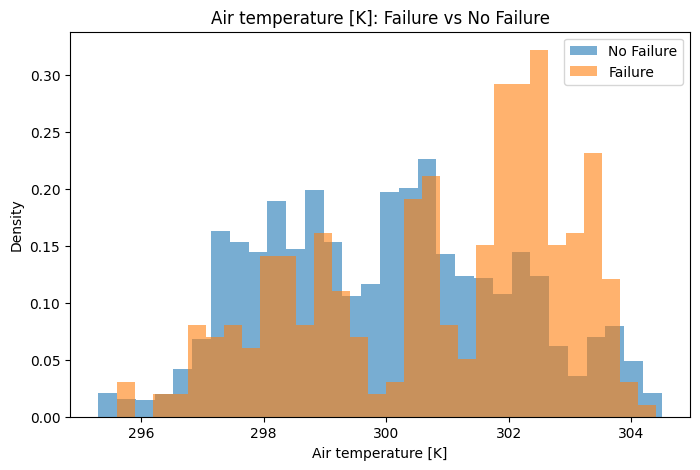

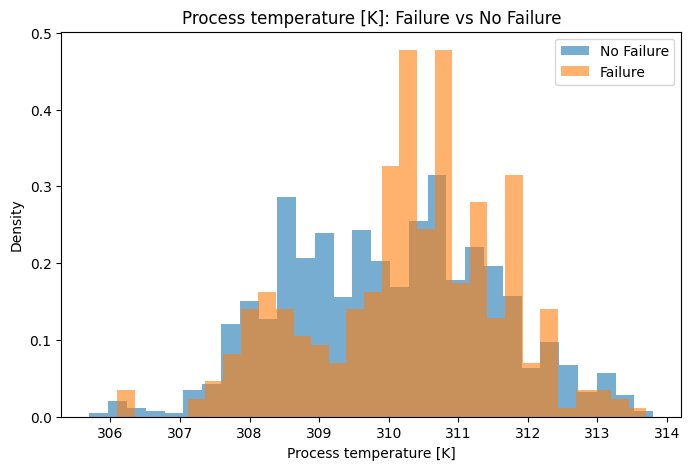

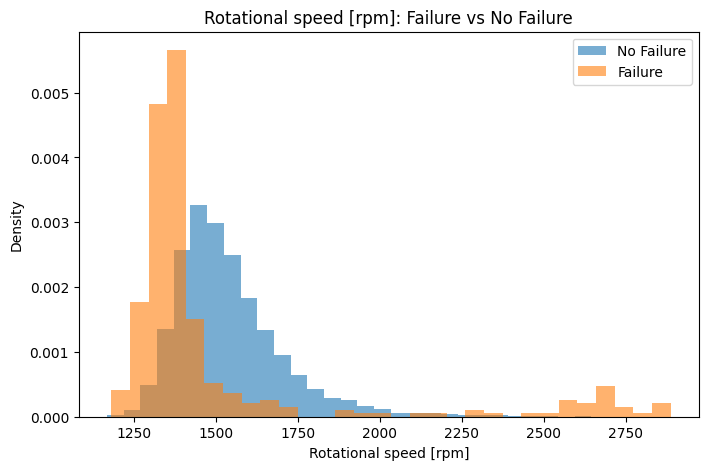

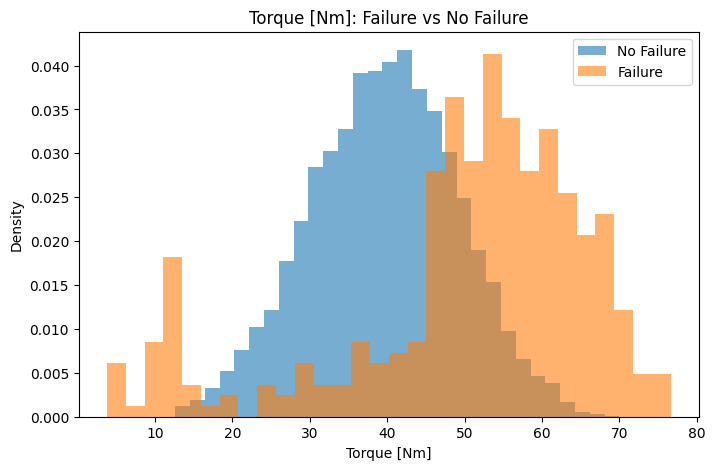

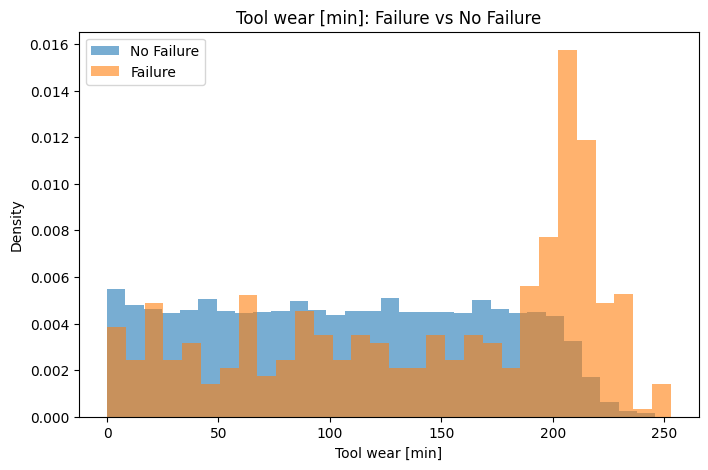

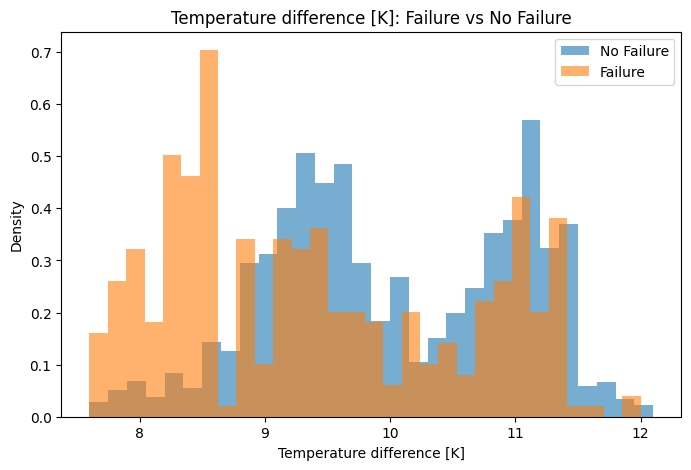

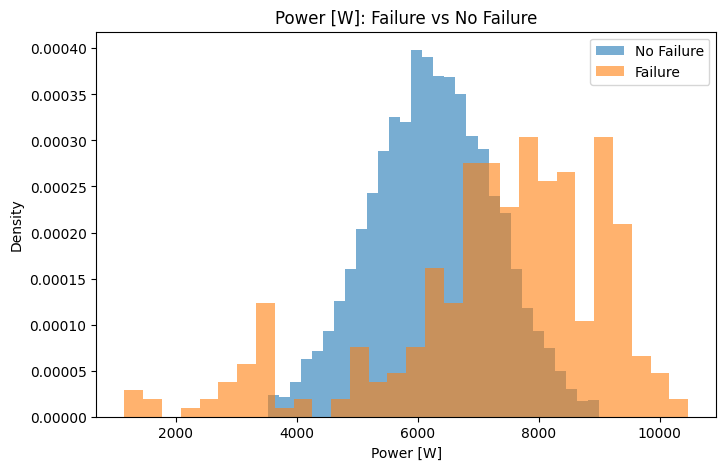


8. BOXPLOTS BY MACHINE FAILURE STATUS


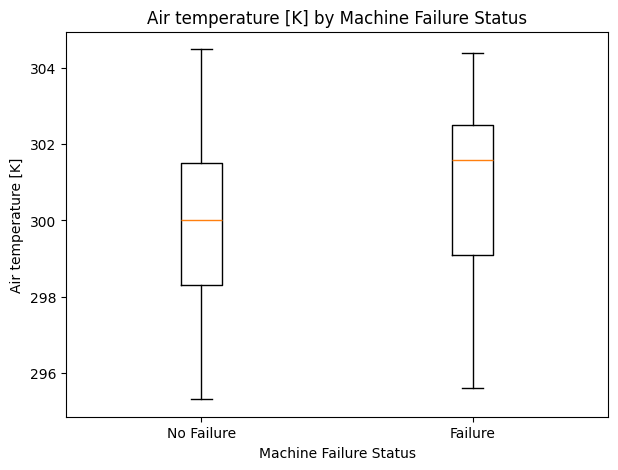

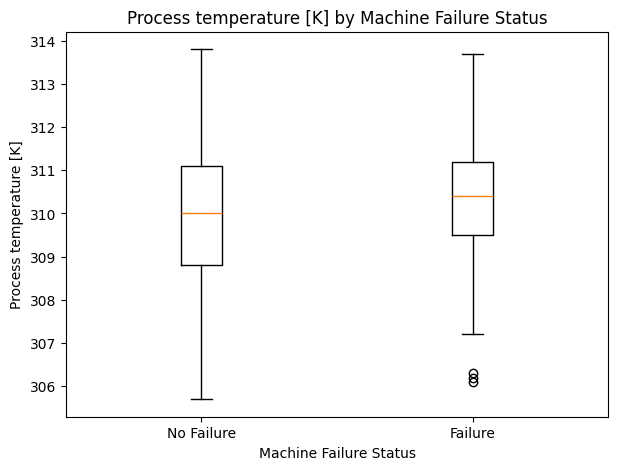

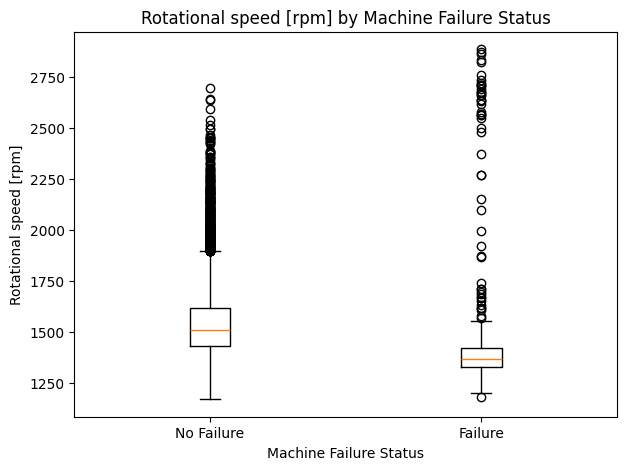

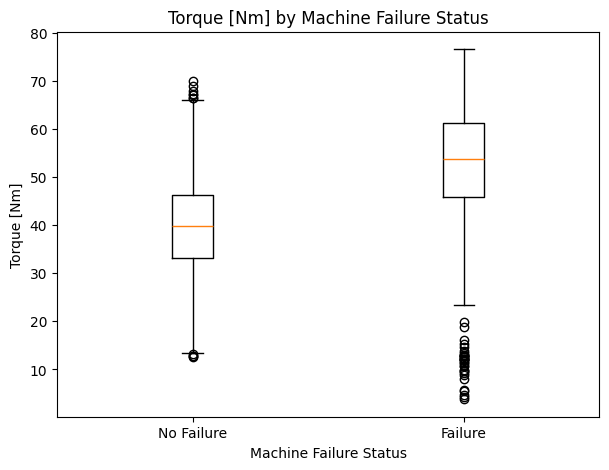

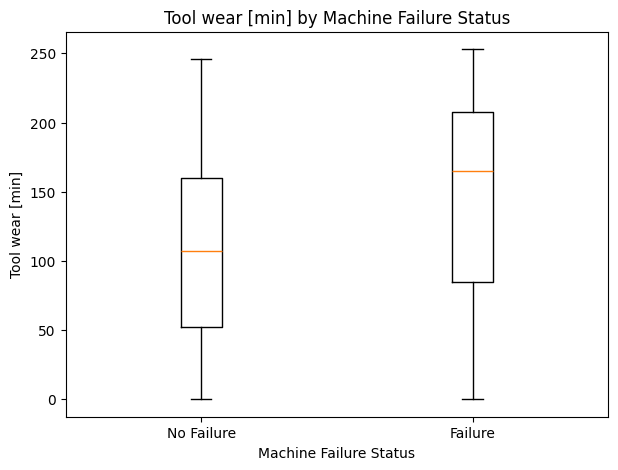

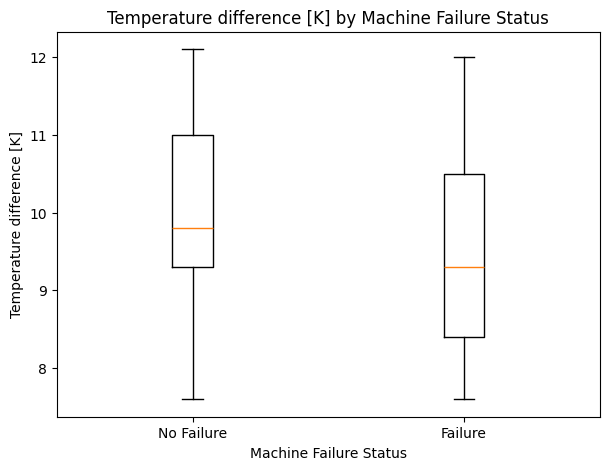

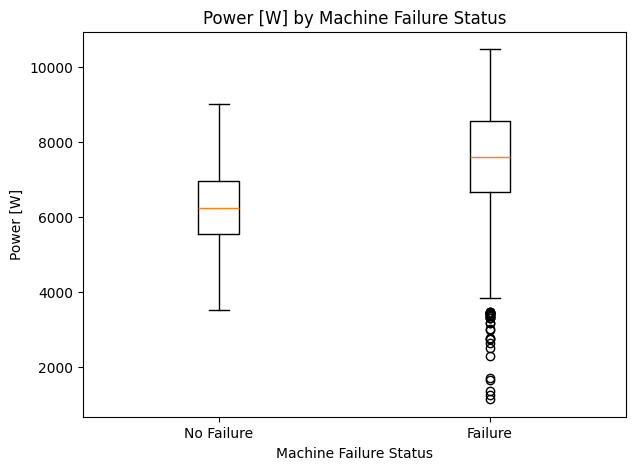


9. FAILURE RATE ACROSS VARIABLE QUARTILES

Air temperature [K]


,Observations,Failures,Failure Rate (%)
Quartile,,,
"(295.29900000000004, 298.3]",2518,53,2.10
"(298.3, 300.1]",2599,57,2.19
"(300.1, 301.5]",2441,57,2.34
"(301.5, 304.5]",2442,172,7.04



Process temperature [K]


,Observations,Failures,Failure Rate (%)
Quartile,,,
"(305.699, 308.8]",2546,63,2.47
"(308.8, 310.1]",2677,68,2.54
"(310.1, 311.1]",2481,118,4.76
"(311.1, 313.8]",2296,90,3.92



Rotational speed [rpm]


...

,Observations,Failures,Failure Rate (%)
Quartile,,,
"(-0.001, 53.0]",2529,55,2.17
"(53.0, 108.0]",2499,59,2.36
"(108.0, 162.0]",2476,52,2.10
"(162.0, 253.0]",2496,173,6.93



Temperature difference [K]


,Observations,Failures,Failure Rate (%)
Quartile,,,
"(7.598999999999999, 9.3]",2559,171,6.68
"(9.3, 9.8]",2505,57,2.28
"(9.8, 11.0]",2794,65,2.33
"(11.0, 12.1]",2142,46,2.15



Power [W]


,Observations,Failures,Failure Rate (%)
Quartile,,,
"(1148.44, 5561.184]",2501,49,1.96
"(5561.184, 6271.027]",2499,22,0.88
"(6271.027, 7003.003]",2500,45,1.80
"(7003.003, 10469.923]",2500,223,8.92


In [ ]:
# ============================================================
# STEP 3: EXPLORATORY ANALYSIS OF PREDICTIVE VARIABLES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create analytical copy
# ------------------------------------------------------------

analysis_df = df.copy()

# Remove temporary variable created in Step 2 if present
if "Failure_Mode_Count" in analysis_df.columns:
    analysis_df = analysis_df.drop(columns=["Failure_Mode_Count"])

# ------------------------------------------------------------
# 2. Engineer physically meaningful variables
# ------------------------------------------------------------

analysis_df["Temperature difference [K]"] = (
    analysis_df["Process temperature [K]"]
    - analysis_df["Air temperature [K]"]
)

# Mechanical power:
# P = torque × angular velocity
# angular velocity = 2*pi*rpm/60
analysis_df["Power [W]"] = (
    analysis_df["Torque [Nm]"]
    * 2
    * np.pi
    * analysis_df["Rotational speed [rpm]"]
    / 60
)

print("=" * 75)
print("1. ANALYTICAL DATASET")
print("=" * 75)

print("Shape:", analysis_df.shape)

print("\nEngineered variables added:")
print("- Temperature difference [K]")
print("- Power [W]")


# ============================================================
# 3. DESCRIPTIVE STATISTICS
# ============================================================

predictive_numeric = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference [K]",
    "Power [W]"
]

print("\n" + "=" * 75)
print("2. DESCRIPTIVE STATISTICS")
print("=" * 75)

descriptive_stats = analysis_df[predictive_numeric].describe().T

descriptive_stats["median"] = (
    analysis_df[predictive_numeric].median()
)

descriptive_stats["skewness"] = (
    analysis_df[predictive_numeric].skew()
)

display(descriptive_stats.round(3))


# ============================================================
# 4. MEAN VALUES BY MACHINE FAILURE STATUS
# ============================================================

print("\n" + "=" * 75)
print("3. MEAN OPERATING CONDITIONS BY FAILURE STATUS")
print("=" * 75)

means_by_failure = (
    analysis_df
    .groupby("Machine failure")[predictive_numeric]
    .mean()
    .T
)

means_by_failure.columns = [
    "No Failure Mean",
    "Failure Mean"
]

means_by_failure["Absolute Difference"] = (
    means_by_failure["Failure Mean"]
    - means_by_failure["No Failure Mean"]
)

means_by_failure["Difference (%)"] = (
    (
        means_by_failure["Failure Mean"]
        - means_by_failure["No Failure Mean"]
    )
    / means_by_failure["No Failure Mean"]
    * 100
)

display(means_by_failure.round(3))


# ============================================================
# 5. MEDIAN VALUES BY FAILURE STATUS
# ============================================================

print("\n" + "=" * 75)
print("4. MEDIAN OPERATING CONDITIONS BY FAILURE STATUS")
print("=" * 75)

medians_by_failure = (
    analysis_df
    .groupby("Machine failure")[predictive_numeric]
    .median()
    .T
)

medians_by_failure.columns = [
    "No Failure Median",
    "Failure Median"
]

display(medians_by_failure.round(3))


# ============================================================
# 6. FAILURE RATE BY PRODUCT TYPE
# ============================================================

print("\n" + "=" * 75)
print("5. FAILURE RATE BY PRODUCT TYPE")
print("=" * 75)

type_analysis = (
    analysis_df
    .groupby("Type")
    .agg(
        Observations=("Machine failure", "count"),
        Failures=("Machine failure", "sum"),
        Failure_Rate=("Machine failure", "mean")
    )
)

type_analysis["Failure Rate (%)"] = (
    type_analysis["Failure_Rate"] * 100
).round(2)

type_analysis = type_analysis.drop(columns="Failure_Rate")

display(type_analysis)


# ============================================================
# 7. CORRELATION WITH MACHINE FAILURE
# ============================================================

print("\n" + "=" * 75)
print("6. NUMERIC CORRELATION WITH MACHINE FAILURE")
print("=" * 75)

correlations = (
    analysis_df[predictive_numeric + ["Machine failure"]]
    .corr()["Machine failure"]
    .drop("Machine failure")
    .sort_values(ascending=False)
)

display(
    correlations
    .rename("Correlation with Machine Failure")
    .to_frame()
    .round(4)
)


# ============================================================
# 8. DISTRIBUTION PLOTS
# ============================================================

print("\n" + "=" * 75)
print("7. DISTRIBUTION PLOTS")
print("=" * 75)

for column in predictive_numeric:

    plt.figure(figsize=(8, 5))

    no_failure = analysis_df.loc[
        analysis_df["Machine failure"] == 0, column
    ]

    failure = analysis_df.loc[
        analysis_df["Machine failure"] == 1, column
    ]

    plt.hist(
        no_failure,
        bins=30,
        alpha=0.6,
        density=True,
        label="No Failure"
    )

    plt.hist(
        failure,
        bins=30,
        alpha=0.6,
        density=True,
        label="Failure"
    )

    plt.xlabel(column)
    plt.ylabel("Density")
    plt.title(f"{column}: Failure vs No Failure")
    plt.legend()
    plt.show()


# ============================================================
# 9. BOXPLOTS BY FAILURE STATUS
# ============================================================

print("\n" + "=" * 75)
print("8. BOXPLOTS BY MACHINE FAILURE STATUS")
print("=" * 75)

for column in predictive_numeric:

    plt.figure(figsize=(7, 5))

    data_to_plot = [
        analysis_df.loc[
            analysis_df["Machine failure"] == 0, column
        ],
        analysis_df.loc[
            analysis_df["Machine failure"] == 1, column
        ]
    ]

    plt.boxplot(
        data_to_plot,
        tick_labels=["No Failure", "Failure"],
        showfliers=True
    )

    plt.ylabel(column)
    plt.xlabel("Machine Failure Status")
    plt.title(f"{column} by Machine Failure Status")
    plt.show()


# ============================================================
# 10. FAILURE RATE ACROSS QUARTILES
# ============================================================

print("\n" + "=" * 75)
print("9. FAILURE RATE ACROSS VARIABLE QUARTILES")
print("=" * 75)

for column in predictive_numeric:

    temp = analysis_df[[column, "Machine failure"]].copy()

    temp["Quartile"] = pd.qcut(
        temp[column],
        q=4,
        duplicates="drop"
    )

    quartile_summary = (
        temp
        .groupby("Quartile", observed=False)
        .agg(
            Observations=("Machine failure", "count"),
            Failures=("Machine failure", "sum"),
            Failure_Rate=("Machine failure", "mean")
        )
    )

    quartile_summary["Failure Rate (%)"] = (
        quartile_summary["Failure_Rate"] * 100
    ).round(2)

    quartile_summary = quartile_summary.drop(
        columns="Failure_Rate"
    )

    print(f"\n{column}")
    display(quartile_summary)

In [ ]:
# ============================================================
# STEP 4: LEAKAGE-SAFE DATA PREPARATION AND TRAIN/TEST SPLIT
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# ============================================================
# 1. DEFINE FEATURES AND TARGET
# ============================================================

print("=" * 75)
print("1. DEFINE MODELLING FEATURES")
print("=" * 75)

feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference [K]",
    "Power [W]"
]

target_column = "Machine failure"

X = analysis_df[feature_columns].copy()
y = analysis_df[target_column].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFeatures used:")
for feature in feature_columns:
    print("-", feature)

print("\nTarget:")
print("-", target_column)


# ============================================================
# 2. CONFIRM EXCLUDED VARIABLES
# ============================================================

print("\n" + "=" * 75)
print("2. VARIABLES EXCLUDED FROM PREDICTION")
print("=" * 75)

excluded_variables = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

for variable in excluded_variables:
    print("-", variable)


# ============================================================
# 3. CHECK TARGET DISTRIBUTION BEFORE SPLIT
# ============================================================

print("\n" + "=" * 75)
print("3. FULL DATASET TARGET DISTRIBUTION")
print("=" * 75)

full_distribution = pd.DataFrame({
    "Count": y.value_counts().sort_index(),
    "Percentage (%)":
        (y.value_counts(normalize=True).sort_index() * 100).round(2)
})

full_distribution.index = [
    "No Failure",
    "Failure"
]

display(full_distribution)


# ============================================================
# 4. STRATIFIED TRAIN/TEST SPLIT
# ============================================================

print("\n" + "=" * 75)
print("4. STRATIFIED TRAIN/TEST SPLIT")
print("=" * 75)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))


# ============================================================
# 5. TRAINING TARGET DISTRIBUTION
# ============================================================

print("\n" + "=" * 75)
print("5. TRAINING SET TARGET DISTRIBUTION")
print("=" * 75)

train_distribution = pd.DataFrame({
    "Count": y_train.value_counts().sort_index(),
    "Percentage (%)":
        (
            y_train.value_counts(normalize=True)
            .sort_index() * 100
        ).round(2)
})

train_distribution.index = [
    "No Failure",
    "Failure"
]

display(train_distribution)


# ============================================================
# 6. TEST TARGET DISTRIBUTION
# ============================================================

print("\n" + "=" * 75)
print("6. TEST SET TARGET DISTRIBUTION")
print("=" * 75)

test_distribution = pd.DataFrame({
    "Count": y_test.value_counts().sort_index(),
    "Percentage (%)":
        (
            y_test.value_counts(normalize=True)
            .sort_index() * 100
        ).round(2)
})

test_distribution.index = [
    "No Failure",
    "Failure"
]

display(test_distribution)


# ============================================================
# 7. DEFINE NUMERIC AND CATEGORICAL FEATURES
# ============================================================

print("\n" + "=" * 75)
print("7. FEATURE TYPES")
print("=" * 75)

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference [K]",
    "Power [W]"
]

categorical_features = [
    "Type"
]

print("Numeric features:")
for feature in numeric_features:
    print("-", feature)

print("\nCategorical features:")
for feature in categorical_features:
    print("-", feature)


# ============================================================
# 8. DEFINE PREPROCESSOR
# ============================================================

print("\n" + "=" * 75)
print("8. PREPROCESSING PIPELINE")
print("=" * 75)

numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Numeric variables: StandardScaler")
print("Categorical variable: OneHotEncoder")
print("Preprocessor successfully created.")


# ============================================================
# 9. CHECK MISSING VALUES AFTER SPLIT
# ============================================================

print("\n" + "=" * 75)
print("9. DATA QUALITY CHECK AFTER SPLIT")
print("=" * 75)

print(
    "Missing values in X_train:",
    X_train.isnull().sum().sum()
)

print(
    "Missing values in X_test:",
    X_test.isnull().sum().sum()
)

print(
    "Missing values in y_train:",
    y_train.isnull().sum()
)

print(
    "Missing values in y_test:",
    y_test.isnull().sum()
)


# ============================================================
# 10. SAVE IDENTIFIERS FOR LATER MAINTENANCE RANKING
# ============================================================

print("\n" + "=" * 75)
print("10. SAVE TEST IDENTIFIERS FOR FINAL PRIORITY SYSTEM")
print("=" * 75)

test_identifiers = analysis_df.loc[
    X_test.index,
    [
        "UDI",
        "Product ID",
        "Type",
        "Machine failure"
    ]
].copy()

print("Identifier records saved:", len(test_identifiers))

display(test_identifiers.head())


# ============================================================
# 11. FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 75)
print("STEP 4 COMPLETED")
print("=" * 75)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nFailure cases in training set:", y_train.sum())
print("Failure cases in testing set:", y_test.sum())

print("\nReady for baseline machine-learning modelling.")

1. DEFINE MODELLING FEATURES
Feature matrix shape: (10000, 8)
Target vector shape: (10000,)

Features used:
- Type
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]
- Temperature difference [K]
- Power [W]

Target:
- Machine failure

2. VARIABLES EXCLUDED FROM PREDICTION
- UDI
- Product ID
- TWF
- HDF
- PWF
- OSF
- RNF

3. FULL DATASET TARGET DISTRIBUTION


,Count,Percentage (%)
No Failure,9661,96.61
Failure,339,3.39



4. STRATIFIED TRAIN/TEST SPLIT
Training observations: 8000
Testing observations: 2000

5. TRAINING SET TARGET DISTRIBUTION


,Count,Percentage (%)
No Failure,7729,96.61
Failure,271,3.39



6. TEST SET TARGET DISTRIBUTION


,Count,Percentage (%)
No Failure,1932,96.6
Failure,68,3.4



7. FEATURE TYPES
Numeric features:
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]
- Temperature difference [K]
- Power [W]

Categorical features:
- Type

8. PREPROCESSING PIPELINE
Numeric variables: StandardScaler
Categorical variable: OneHotEncoder
Preprocessor successfully created.

9. DATA QUALITY CHECK AFTER SPLIT
Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0

10. SAVE TEST IDENTIFIERS FOR FINAL PRIORITY SYSTEM
Identifier records saved: 2000


,UDI,Product ID,Type,Machine failure
2997,2998,L50177,L,0
4871,4872,L52051,L,0
3858,3859,L51038,L,0
951,952,H30365,H,0
6463,6464,H35877,H,0



STEP 4 COMPLETED
X_train shape: (8000, 8)
X_test shape: (2000, 8)

Failure cases in training set: 271
Failure cases in testing set: 68

Ready for baseline machine-learning modelling.


1. TRAINING DUMMY CLASSIFIER

Dummy Classifier

Classification Report:

              precision    recall  f1-score   support

           0     0.9660    1.0000    0.9827      1932
           1     0.0000    0.0000    0.0000        68

    accuracy                         0.9660      2000
   macro avg     0.4830    0.5000    0.4914      2000
weighted avg     0.9332    0.9660    0.9493      2000

Confusion Matrix:
[[1932    0]
 [  68    0]]

Metrics:
Accuracy  : 0.9660
Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000
ROC-AUC   : 0.5000
PR-AUC    : 0.0340

2. TRAINING LOGISTIC REGRESSION

Logistic Regression

Classification Report:

              precision    recall  f1-score   support

           0     0.9717    0.9953    0.9834      1932
           1     0.5714    0.1765    0.2697        68

    accuracy                         0.9675      2000
   macro avg     0.7716    0.5859    0.6265      2000
weighted avg     0.9581    0.9675    0.9591      2000

Confusion Matrix:
[[1923  

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Dummy Classifier,0.9660,0.0000,0.0000,0.0000,0.5000,0.0340
1,Logistic Regression,0.9675,0.5714,0.1765,0.2697,0.9252,0.4606



4. ROC CURVE


<Figure size 700x600 with 0 Axes>

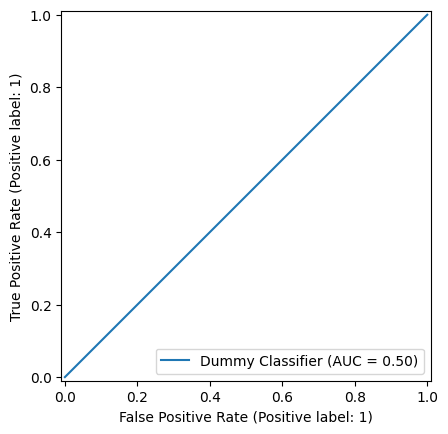

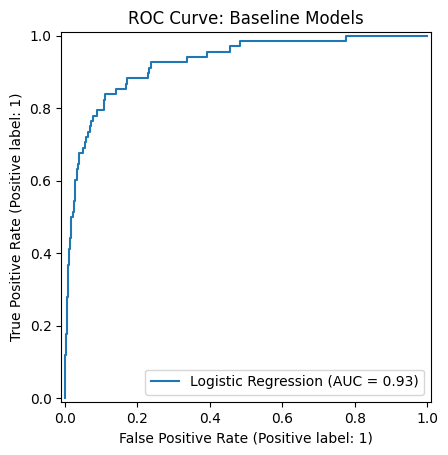


5. PRECISION-RECALL CURVE


<Figure size 700x600 with 0 Axes>

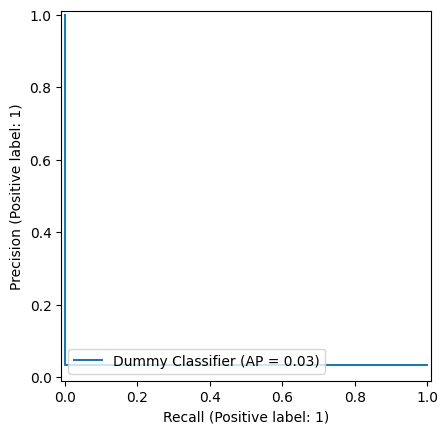

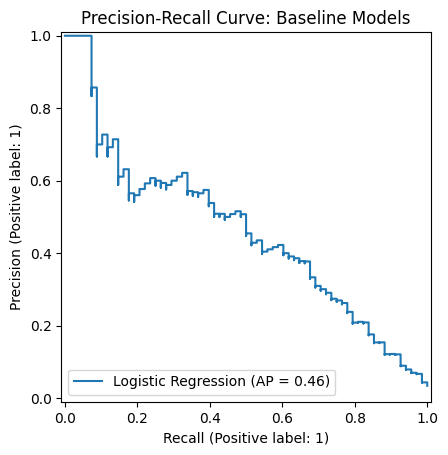


STEP 5 COMPLETED
Baseline models successfully evaluated.


In [ ]:
# ============================================================
# STEP 5: BASELINE MODELS
# Dummy Classifier + Logistic Regression
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)


# ============================================================
# 1. EVALUATION FUNCTION
# ============================================================

def evaluate_model(model_name, model, X_test, y_test):

    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = None

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    if y_prob is not None:
        roc_auc = roc_auc_score(
            y_test,
            y_prob
        )

        pr_auc = average_precision_score(
            y_test,
            y_prob
        )
    else:
        roc_auc = np.nan
        pr_auc = np.nan

    results = {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    }

    print("\n" + "=" * 75)
    print(model_name)
    print("=" * 75)

    print("\nClassification Report:\n")

    print(
        classification_report(
            y_test,
            y_pred,
            digits=4,
            zero_division=0
        )
    )

    print("Confusion Matrix:")

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    print(cm)

    print("\nMetrics:")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")
    print(f"ROC-AUC   : {roc_auc:.4f}")
    print(f"PR-AUC    : {pr_auc:.4f}")

    return results, y_pred, y_prob


# ============================================================
# 2. DUMMY CLASSIFIER
# ============================================================

print("=" * 75)
print("1. TRAINING DUMMY CLASSIFIER")
print("=" * 75)

dummy_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)

dummy_pipeline.fit(
    X_train,
    y_train
)

dummy_results, dummy_pred, dummy_prob = evaluate_model(
    "Dummy Classifier",
    dummy_pipeline,
    X_test,
    y_test
)


# ============================================================
# 3. LOGISTIC REGRESSION
# ============================================================

print("\n" + "=" * 75)
print("2. TRAINING LOGISTIC REGRESSION")
print("=" * 75)

logistic_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

logistic_pipeline.fit(
    X_train,
    y_train
)

logistic_results, logistic_pred, logistic_prob = evaluate_model(
    "Logistic Regression",
    logistic_pipeline,
    X_test,
    y_test
)


# ============================================================
# 4. BASELINE COMPARISON TABLE
# ============================================================

print("\n" + "=" * 75)
print("3. BASELINE MODEL COMPARISON")
print("=" * 75)

baseline_results = pd.DataFrame([
    dummy_results,
    logistic_results
])

display(
    baseline_results.round(4)
)


# ============================================================
# 5. ROC CURVE
# ============================================================

print("\n" + "=" * 75)
print("4. ROC CURVE")
print("=" * 75)

plt.figure(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test,
    dummy_prob,
    name="Dummy Classifier"
)

RocCurveDisplay.from_predictions(
    y_test,
    logistic_prob,
    name="Logistic Regression"
)

plt.title("ROC Curve: Baseline Models")
plt.show()


# ============================================================
# 6. PRECISION-RECALL CURVE
# ============================================================

print("\n" + "=" * 75)
print("5. PRECISION-RECALL CURVE")
print("=" * 75)

plt.figure(figsize=(7, 6))

PrecisionRecallDisplay.from_predictions(
    y_test,
    dummy_prob,
    name="Dummy Classifier"
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    logistic_prob,
    name="Logistic Regression"
)

plt.title("Precision-Recall Curve: Baseline Models")
plt.show()


# ============================================================
# 7. STORE RESULTS FOR LATER COMPARISON
# ============================================================

all_model_results = baseline_results.copy()

print("\n" + "=" * 75)
print("STEP 5 COMPLETED")
print("=" * 75)

print("Baseline models successfully evaluated.")

In [ ]:
# ============================================================
# STEP 6: IMBALANCE-AWARE MULTIPLE ALGORITHM COMPARISON
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# ============================================================
# 1. LOAD XGBOOST
# ============================================================

try:
    from xgboost import XGBClassifier
    xgb_available = True
    print("XGBoost successfully imported.")
except Exception as e:
    xgb_available = False
    print("XGBoost could not be imported.")
    print(e)


# ============================================================
# 2. CALCULATE CLASS IMBALANCE WEIGHT
# ============================================================

print("\n" + "=" * 80)
print("1. CLASS IMBALANCE INFORMATION")
print("=" * 80)

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Training non-failures:", negative_count)
print("Training failures:", positive_count)

print(
    f"scale_pos_weight for XGBoost: "
    f"{scale_pos_weight:.4f}"
)


# ============================================================
# 3. DEFINE MODELS
# ============================================================

print("\n" + "=" * 80)
print("2. DEFINING MODELS")
print("=" * 80)

models = {}


# ------------------------------------------------------------
# Balanced Logistic Regression
# ------------------------------------------------------------

models["Balanced Logistic Regression"] = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42
            )
        )
    ]
)


# ------------------------------------------------------------
# Decision Tree
# ------------------------------------------------------------

models["Decision Tree"] = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)


# ------------------------------------------------------------
# Balanced Decision Tree
# ------------------------------------------------------------

models["Balanced Decision Tree"] = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)


# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------

models["Random Forest"] = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)


# ------------------------------------------------------------
# Balanced Random Forest
# ------------------------------------------------------------

models["Balanced Random Forest"] = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)


# ------------------------------------------------------------
# Gradient Boosting
# ------------------------------------------------------------

models["Gradient Boosting"] = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            GradientBoostingClassifier(
                random_state=42
            )
        )
    ]
)


# ------------------------------------------------------------
# XGBoost
# ------------------------------------------------------------

if xgb_available:

    models["XGBoost"] = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                XGBClassifier(
                    n_estimators=300,
                    learning_rate=0.05,
                    max_depth=4,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    objective="binary:logistic",
                    eval_metric="logloss",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )


# ------------------------------------------------------------
# Balanced XGBoost
# ------------------------------------------------------------

if xgb_available:

    models["Balanced XGBoost"] = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                XGBClassifier(
                    n_estimators=300,
                    learning_rate=0.05,
                    max_depth=4,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    scale_pos_weight=scale_pos_weight,
                    objective="binary:logistic",
                    eval_metric="logloss",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )


print("Models prepared:")

for name in models.keys():
    print("-", name)


# ============================================================
# 4. TRAIN AND EVALUATE ALL MODELS
# ============================================================

print("\n" + "=" * 80)
print("3. TRAINING AND EVALUATING MODELS")
print("=" * 80)

comparison_results = []

model_predictions = {}
model_probabilities = {}
trained_models = {}


for model_name, model in models.items():

    print("\n" + "-" * 80)
    print("Training:", model_name)
    print("-" * 80)

    # Train
    model.fit(
        X_train,
        y_train
    )

    # Predictions
    y_pred = model.predict(
        X_test
    )

    y_prob = model.predict_proba(
        X_test
    )[:, 1]

    # Store
    trained_models[model_name] = model
    model_predictions[model_name] = y_pred
    model_probabilities[model_name] = y_prob

    # Metrics
    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )

    pr_auc = average_precision_score(
        y_test,
        y_prob
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1-score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

    print(
        f"Accuracy    : {accuracy:.4f}"
    )

    print(
        f"Precision   : {precision:.4f}"
    )

    print(
        f"Recall      : {recall:.4f}"
    )

    print(
        f"Specificity : {specificity:.4f}"
    )

    print(
        f"F1-score    : {f1:.4f}"
    )

    print(
        f"ROC-AUC     : {roc_auc:.4f}"
    )

    print(
        f"PR-AUC      : {pr_auc:.4f}"
    )

    print(
        f"TN={tn}, FP={fp}, FN={fn}, TP={tp}"
    )


# ============================================================
# 5. ADD PREVIOUS BASELINES
# ============================================================

previous_results = pd.DataFrame([
    {
        "Model": "Dummy Classifier",
        "Accuracy": accuracy_score(
            y_test,
            dummy_pred
        ),
        "Precision": precision_score(
            y_test,
            dummy_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            dummy_pred,
            zero_division=0
        ),
        "Specificity": 1.0,
        "F1-score": f1_score(
            y_test,
            dummy_pred,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            dummy_prob
        ),
        "PR-AUC": average_precision_score(
            y_test,
            dummy_prob
        )
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(
            y_test,
            logistic_pred
        ),
        "Precision": precision_score(
            y_test,
            logistic_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            logistic_pred,
            zero_division=0
        ),
        "Specificity":
            confusion_matrix(
                y_test,
                logistic_pred
            )[0, 0]
            /
            confusion_matrix(
                y_test,
                logistic_pred
            )[0].sum(),
        "F1-score": f1_score(
            y_test,
            logistic_pred,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            logistic_prob
        ),
        "PR-AUC": average_precision_score(
            y_test,
            logistic_prob
        )
    }
])


new_results = pd.DataFrame(
    comparison_results
)

all_algorithm_results = pd.concat(
    [
        previous_results,
        new_results
    ],
    ignore_index=True
)


# ============================================================
# 6. COMPLETE MODEL COMPARISON TABLE
# ============================================================

print("\n" + "=" * 80)
print("4. COMPLETE MODEL COMPARISON")
print("=" * 80)

comparison_columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
]

display(
    all_algorithm_results[
        comparison_columns
    ].round(4)
)


# ============================================================
# 7. RANK BY PR-AUC
# ============================================================

print("\n" + "=" * 80)
print("5. MODEL RANKING BY PR-AUC")
print("=" * 80)

rank_pr = (
    all_algorithm_results[
        comparison_columns
    ]
    .sort_values(
        "PR-AUC",
        ascending=False
    )
)

display(
    rank_pr.round(4)
)


# ============================================================
# 8. RANK BY RECALL
# ============================================================

print("\n" + "=" * 80)
print("6. MODEL RANKING BY FAILURE RECALL")
print("=" * 80)

rank_recall = (
    all_algorithm_results[
        comparison_columns
    ]
    .sort_values(
        "Recall",
        ascending=False
    )
)

display(
    rank_recall.round(4)
)


# ============================================================
# 9. RANK BY F1-SCORE
# ============================================================

print("\n" + "=" * 80)
print("7. MODEL RANKING BY F1-SCORE")
print("=" * 80)

rank_f1 = (
    all_algorithm_results[
        comparison_columns
    ]
    .sort_values(
        "F1-score",
        ascending=False
    )
)

display(
    rank_f1.round(4)
)


# ============================================================
# 10. IDENTIFY BEST MODELS
# ============================================================

print("\n" + "=" * 80)
print("8. INITIAL BEST MODELS")
print("=" * 80)

best_pr_model = (
    all_algorithm_results
    .loc[
        all_algorithm_results["PR-AUC"].idxmax(),
        "Model"
    ]
)

best_recall_model = (
    all_algorithm_results
    .loc[
        all_algorithm_results["Recall"].idxmax(),
        "Model"
    ]
)

best_f1_model = (
    all_algorithm_results
    .loc[
        all_algorithm_results["F1-score"].idxmax(),
        "Model"
    ]
)

best_roc_model = (
    all_algorithm_results
    .loc[
        all_algorithm_results["ROC-AUC"].idxmax(),
        "Model"
    ]
)

print(
    "Best PR-AUC model:",
    best_pr_model
)

print(
    "Best Recall model:",
    best_recall_model
)

print(
    "Best F1-score model:",
    best_f1_model
)

print(
    "Best ROC-AUC model:",
    best_roc_model
)


# ============================================================
# 11. FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 80)
print("STEP 6 COMPLETED")
print("=" * 80)

print(
    "Initial multi-algorithm comparison completed successfully."
)

XGBoost successfully imported.

1. CLASS IMBALANCE INFORMATION
Training non-failures: 7729
Training failures: 271
scale_pos_weight for XGBoost: 28.5203

2. DEFINING MODELS
Models prepared:
- Balanced Logistic Regression
- Decision Tree
- Balanced Decision Tree
- Random Forest
- Balanced Random Forest
- Gradient Boosting
- XGBoost
- Balanced XGBoost

3. TRAINING AND EVALUATING MODELS

--------------------------------------------------------------------------------
Training: Balanced Logistic Regression
--------------------------------------------------------------------------------
Accuracy    : 0.8590
Precision   : 0.1777
Recall      : 0.8676
Specificity : 0.8587
F1-score    : 0.2950
ROC-AUC     : 0.9339
PR-AUC      : 0.4660
TN=1659, FP=273, FN=9, TP=59

--------------------------------------------------------------------------------
Training: Decision Tree
--------------------------------------------------------------------------------
Accuracy    : 0.9850
Precision   : 0.8065
Recall 

,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
0,Dummy Classifier,0.9660,0.0000,0.0000,1.0000,0.0000,0.5000,0.0340
1,Logistic Regression,0.9675,0.5714,0.1765,0.9953,0.2697,0.9252,0.4606
2,Balanced Logistic Regression,0.8590,0.1777,0.8676,0.8587,0.2950,0.9339,0.4660
3,Decision Tree,0.9850,0.8065,0.7353,0.9938,0.7692,0.8645,0.6020
4,Balanced Decision Tree,0.9850,0.8276,0.7059,0.9948,0.7619,0.8504,0.5942
5,Random Forest,0.9915,0.9474,0.7941,0.9984,0.8640,0.9792,0.8853
6,Balanced Random Forest,0.9895,0.9434,0.7353,0.9984,0.8264,0.9780,0.8630
7,Gradient Boosting,0.9910,0.9464,0.7794,0.9984,0.8548,0.9759,0.8998
8,XGBoost,0.9900,0.9286,0.7647,0.9979,0.8387,0.9823,0.8878
9,Balanced XGBoost,0.9815,0.6742,0.8824,0.9850,0.7643,0.9783,0.8868



5. MODEL RANKING BY PR-AUC


,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
7,Gradient Boosting,0.9910,0.9464,0.7794,0.9984,0.8548,0.9759,0.8998
8,XGBoost,0.9900,0.9286,0.7647,0.9979,0.8387,0.9823,0.8878
9,Balanced XGBoost,0.9815,0.6742,0.8824,0.9850,0.7643,0.9783,0.8868
5,Random Forest,0.9915,0.9474,0.7941,0.9984,0.8640,0.9792,0.8853
6,Balanced Random Forest,0.9895,0.9434,0.7353,0.9984,0.8264,0.9780,0.8630
3,Decision Tree,0.9850,0.8065,0.7353,0.9938,0.7692,0.8645,0.6020
4,Balanced Decision Tree,0.9850,0.8276,0.7059,0.9948,0.7619,0.8504,0.5942
2,Balanced Logistic Regression,0.8590,0.1777,0.8676,0.8587,0.2950,0.9339,0.4660
1,Logistic Regression,0.9675,0.5714,0.1765,0.9953,0.2697,0.9252,0.4606
0,Dummy Classifier,0.9660,0.0000,0.0000,1.0000,0.0000,0.5000,0.0340



6. MODEL RANKING BY FAILURE RECALL


,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
9,Balanced XGBoost,0.9815,0.6742,0.8824,0.9850,0.7643,0.9783,0.8868
2,Balanced Logistic Regression,0.8590,0.1777,0.8676,0.8587,0.2950,0.9339,0.4660
5,Random Forest,0.9915,0.9474,0.7941,0.9984,0.8640,0.9792,0.8853
7,Gradient Boosting,0.9910,0.9464,0.7794,0.9984,0.8548,0.9759,0.8998
8,XGBoost,0.9900,0.9286,0.7647,0.9979,0.8387,0.9823,0.8878
3,Decision Tree,0.9850,0.8065,0.7353,0.9938,0.7692,0.8645,0.6020
6,Balanced Random Forest,0.9895,0.9434,0.7353,0.9984,0.8264,0.9780,0.8630
4,Balanced Decision Tree,0.9850,0.8276,0.7059,0.9948,0.7619,0.8504,0.5942
1,Logistic Regression,0.9675,0.5714,0.1765,0.9953,0.2697,0.9252,0.4606
0,Dummy Classifier,0.9660,0.0000,0.0000,1.0000,0.0000,0.5000,0.0340



7. MODEL RANKING BY F1-SCORE


,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
5,Random Forest,0.9915,0.9474,0.7941,0.9984,0.8640,0.9792,0.8853
7,Gradient Boosting,0.9910,0.9464,0.7794,0.9984,0.8548,0.9759,0.8998
8,XGBoost,0.9900,0.9286,0.7647,0.9979,0.8387,0.9823,0.8878
6,Balanced Random Forest,0.9895,0.9434,0.7353,0.9984,0.8264,0.9780,0.8630
3,Decision Tree,0.9850,0.8065,0.7353,0.9938,0.7692,0.8645,0.6020
9,Balanced XGBoost,0.9815,0.6742,0.8824,0.9850,0.7643,0.9783,0.8868
4,Balanced Decision Tree,0.9850,0.8276,0.7059,0.9948,0.7619,0.8504,0.5942
2,Balanced Logistic Regression,0.8590,0.1777,0.8676,0.8587,0.2950,0.9339,0.4660
1,Logistic Regression,0.9675,0.5714,0.1765,0.9953,0.2697,0.9252,0.4606
0,Dummy Classifier,0.9660,0.0000,0.0000,1.0000,0.0000,0.5000,0.0340



8. INITIAL BEST MODELS
Best PR-AUC model: Gradient Boosting
Best Recall model: Balanced XGBoost
Best F1-score model: Random Forest
Best ROC-AUC model: XGBoost

STEP 6 COMPLETED
Initial multi-algorithm comparison completed successfully.


In [ ]:
# ============================================================
# STEP 7: STRATIFIED CROSS-VALIDATION OF TOP MODELS
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from xgboost import XGBClassifier


# ============================================================
# 1. DEFINE STRATIFIED CROSS-VALIDATION
# ============================================================

print("=" * 80)
print("1. CROSS-VALIDATION DESIGN")
print("=" * 80)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation method: StratifiedKFold")
print("Number of folds: 5")
print("Shuffle: True")
print("Random state: 42")

print("\nTraining observations used:", len(X_train))
print("Training failures:", int(y_train.sum()))
print(
    "Training failure rate:",
    f"{y_train.mean() * 100:.2f}%"
)


# ============================================================
# 2. CLASS IMBALANCE RATIO
# ============================================================

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight_cv = (
    negative_count / positive_count
)

print(
    "\nXGBoost scale_pos_weight:",
    round(scale_pos_weight_cv, 4)
)


# ============================================================
# 3. DEFINE TOP FOUR MODELS
# ============================================================

print("\n" + "=" * 80)
print("2. TOP MODELS SELECTED FOR CROSS-VALIDATION")
print("=" * 80)


cv_models = {

    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    "Random Forest": Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=300,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    ),


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    "Gradient Boosting": Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                GradientBoostingClassifier(
                    random_state=42
                )
            )
        ]
    ),


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    "XGBoost": Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                XGBClassifier(
                    n_estimators=300,
                    learning_rate=0.05,
                    max_depth=4,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    objective="binary:logistic",
                    eval_metric="logloss",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    ),


    # --------------------------------------------------------
    # Balanced XGBoost
    # --------------------------------------------------------

    "Balanced XGBoost": Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                XGBClassifier(
                    n_estimators=300,
                    learning_rate=0.05,
                    max_depth=4,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    scale_pos_weight=scale_pos_weight_cv,
                    objective="binary:logistic",
                    eval_metric="logloss",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )
}


for model_name in cv_models:
    print("-", model_name)


# ============================================================
# 4. DEFINE CV SCORING METRICS
# ============================================================

print("\n" + "=" * 80)
print("3. CROSS-VALIDATION METRICS")
print("=" * 80)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

for metric in scoring:
    print("-", metric)


# ============================================================
# 5. RUN CROSS-VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("4. RUNNING 5-FOLD STRATIFIED CROSS-VALIDATION")
print("=" * 80)


cv_detailed_results = {}
cv_summary_rows = []


for model_name, model in cv_models.items():

    print("\n" + "-" * 80)
    print("Cross-validating:", model_name)
    print("-" * 80)

    scores = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1
    )

    cv_detailed_results[model_name] = scores


    # --------------------------------------------------------
    # Mean and standard deviation
    # --------------------------------------------------------

    accuracy_mean = scores[
        "test_accuracy"
    ].mean()

    accuracy_std = scores[
        "test_accuracy"
    ].std()

    precision_mean = scores[
        "test_precision"
    ].mean()

    precision_std = scores[
        "test_precision"
    ].std()

    recall_mean = scores[
        "test_recall"
    ].mean()

    recall_std = scores[
        "test_recall"
    ].std()

    f1_mean = scores[
        "test_f1"
    ].mean()

    f1_std = scores[
        "test_f1"
    ].std()

    roc_mean = scores[
        "test_roc_auc"
    ].mean()

    roc_std = scores[
        "test_roc_auc"
    ].std()

    pr_mean = scores[
        "test_pr_auc"
    ].mean()

    pr_std = scores[
        "test_pr_auc"
    ].std()


    cv_summary_rows.append({

        "Model": model_name,

        "Accuracy Mean":
            accuracy_mean,

        "Accuracy SD":
            accuracy_std,

        "Precision Mean":
            precision_mean,

        "Precision SD":
            precision_std,

        "Recall Mean":
            recall_mean,

        "Recall SD":
            recall_std,

        "F1 Mean":
            f1_mean,

        "F1 SD":
            f1_std,

        "ROC-AUC Mean":
            roc_mean,

        "ROC-AUC SD":
            roc_std,

        "PR-AUC Mean":
            pr_mean,

        "PR-AUC SD":
            pr_std

    })


    print(
        f"Accuracy : "
        f"{accuracy_mean:.4f} ± "
        f"{accuracy_std:.4f}"
    )

    print(
        f"Precision: "
        f"{precision_mean:.4f} ± "
        f"{precision_std:.4f}"
    )

    print(
        f"Recall   : "
        f"{recall_mean:.4f} ± "
        f"{recall_std:.4f}"
    )

    print(
        f"F1-score : "
        f"{f1_mean:.4f} ± "
        f"{f1_std:.4f}"
    )

    print(
        f"ROC-AUC  : "
        f"{roc_mean:.4f} ± "
        f"{roc_std:.4f}"
    )

    print(
        f"PR-AUC   : "
        f"{pr_mean:.4f} ± "
        f"{pr_std:.4f}"
    )


# ============================================================
# 6. SUMMARY TABLE
# ============================================================

cv_summary = pd.DataFrame(
    cv_summary_rows
)

print("\n" + "=" * 80)
print("5. CROSS-VALIDATION SUMMARY")
print("=" * 80)

display(
    cv_summary.round(4)
)


# ============================================================
# 7. COMPACT THESIS TABLE
# ============================================================

print("\n" + "=" * 80)
print("6. COMPACT CROSS-VALIDATION TABLE")
print("=" * 80)


compact_cv = pd.DataFrame({

    "Model":
        cv_summary["Model"],

    "Precision":
        cv_summary.apply(
            lambda row:
            f"{row['Precision Mean']:.3f} ± "
            f"{row['Precision SD']:.3f}",
            axis=1
        ),

    "Recall":
        cv_summary.apply(
            lambda row:
            f"{row['Recall Mean']:.3f} ± "
            f"{row['Recall SD']:.3f}",
            axis=1
        ),

    "F1":
        cv_summary.apply(
            lambda row:
            f"{row['F1 Mean']:.3f} ± "
            f"{row['F1 SD']:.3f}",
            axis=1
        ),

    "ROC-AUC":
        cv_summary.apply(
            lambda row:
            f"{row['ROC-AUC Mean']:.3f} ± "
            f"{row['ROC-AUC SD']:.3f}",
            axis=1
        ),

    "PR-AUC":
        cv_summary.apply(
            lambda row:
            f"{row['PR-AUC Mean']:.3f} ± "
            f"{row['PR-AUC SD']:.3f}",
            axis=1
        )
})

display(compact_cv)


# ============================================================
# 8. RANK MODELS BY CROSS-VALIDATED PR-AUC
# ============================================================

print("\n" + "=" * 80)
print("7. RANKING BY CROSS-VALIDATED PR-AUC")
print("=" * 80)

cv_pr_ranking = (
    cv_summary[
        [
            "Model",
            "PR-AUC Mean",
            "PR-AUC SD",
            "Recall Mean",
            "Precision Mean",
            "F1 Mean",
            "ROC-AUC Mean"
        ]
    ]
    .sort_values(
        by="PR-AUC Mean",
        ascending=False
    )
)

display(
    cv_pr_ranking.round(4)
)


# ============================================================
# 9. RANK BY F1
# ============================================================

print("\n" + "=" * 80)
print("8. RANKING BY CROSS-VALIDATED F1")
print("=" * 80)

cv_f1_ranking = (
    cv_summary[
        [
            "Model",
            "F1 Mean",
            "F1 SD",
            "Recall Mean",
            "Precision Mean",
            "PR-AUC Mean",
            "ROC-AUC Mean"
        ]
    ]
    .sort_values(
        by="F1 Mean",
        ascending=False
    )
)

display(
    cv_f1_ranking.round(4)
)


# ============================================================
# 10. FOLD-BY-FOLD RESULTS
# ============================================================

print("\n" + "=" * 80)
print("9. FOLD-BY-FOLD PR-AUC AND RECALL")
print("=" * 80)


for model_name, scores in cv_detailed_results.items():

    fold_table = pd.DataFrame({

        "Fold":
            np.arange(
                1,
                6
            ),

        "PR-AUC":
            scores[
                "test_pr_auc"
            ],

        "ROC-AUC":
            scores[
                "test_roc_auc"
            ],

        "Recall":
            scores[
                "test_recall"
            ],

        "Precision":
            scores[
                "test_precision"
            ],

        "F1":
            scores[
                "test_f1"
            ]
    })

    print(
        f"\n{model_name}"
    )

    display(
        fold_table.round(4)
    )


# ============================================================
# 11. IDENTIFY CV WINNERS
# ============================================================

print("\n" + "=" * 80)
print("10. CROSS-VALIDATION WINNERS")
print("=" * 80)


best_cv_pr = cv_summary.loc[
    cv_summary[
        "PR-AUC Mean"
    ].idxmax(),
    "Model"
]


best_cv_f1 = cv_summary.loc[
    cv_summary[
        "F1 Mean"
    ].idxmax(),
    "Model"
]


best_cv_recall = cv_summary.loc[
    cv_summary[
        "Recall Mean"
    ].idxmax(),
    "Model"
]


best_cv_roc = cv_summary.loc[
    cv_summary[
        "ROC-AUC Mean"
    ].idxmax(),
    "Model"
]


print(
    "Best cross-validated PR-AUC:",
    best_cv_pr
)

print(
    "Best cross-validated F1:",
    best_cv_f1
)

print(
    "Best cross-validated Recall:",
    best_cv_recall
)

print(
    "Best cross-validated ROC-AUC:",
    best_cv_roc
)


# ============================================================
# 12. FINISH
# ============================================================

print("\n" + "=" * 80)
print("STEP 7 COMPLETED")
print("=" * 80)

print(
    "Top algorithms evaluated using "
    "5-fold stratified cross-validation."
)

1. CROSS-VALIDATION DESIGN
Cross-validation method: StratifiedKFold
Number of folds: 5
Shuffle: True
Random state: 42

Training observations used: 8000
Training failures: 271
Training failure rate: 3.39%

XGBoost scale_pos_weight: 28.5203

2. TOP MODELS SELECTED FOR CROSS-VALIDATION
- Random Forest
- Gradient Boosting
- XGBoost
- Balanced XGBoost

3. CROSS-VALIDATION METRICS
- accuracy
- precision
- recall
- f1
- roc_auc
- pr_auc

4. RUNNING 5-FOLD STRATIFIED CROSS-VALIDATION

--------------------------------------------------------------------------------
Cross-validating: Random Forest
--------------------------------------------------------------------------------
Accuracy : 0.9904 ± 0.0020
Precision: 0.9767 ± 0.0136
Recall   : 0.7345 ± 0.0678
F1-score : 0.8363 ± 0.0401
ROC-AUC  : 0.9752 ± 0.0143
PR-AUC   : 0.8800 ± 0.0322

--------------------------------------------------------------------------------
Cross-validating: Gradient Boosting
--------------------------------------------

,Model,Accuracy Mean,Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,F1 Mean,F1 SD,ROC-AUC Mean,ROC-AUC SD,PR-AUC Mean,PR-AUC SD
0,Random Forest,0.9904,0.0020,0.9767,0.0136,0.7345,0.0678,0.8363,0.0401,0.9752,0.0143,0.8800,0.0322
1,Gradient Boosting,0.9895,0.0012,0.9223,0.0315,0.7567,0.0577,0.8290,0.0255,0.9808,0.0130,0.8847,0.0130
2,XGBoost,0.9874,0.0019,0.8892,0.0447,0.7198,0.0599,0.7933,0.0351,0.9785,0.0121,0.8476,0.0348
3,Balanced XGBoost,0.9821,0.0030,0.7002,0.0432,0.8302,0.0301,0.7594,0.0361,0.9780,0.0103,0.8308,0.0437



6. COMPACT CROSS-VALIDATION TABLE


,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.977 ± 0.014,0.735 ± 0.068,0.836 ± 0.040,0.975 ± 0.014,0.880 ± 0.032
1,Gradient Boosting,0.922 ± 0.032,0.757 ± 0.058,0.829 ± 0.025,0.981 ± 0.013,0.885 ± 0.013
2,XGBoost,0.889 ± 0.045,0.720 ± 0.060,0.793 ± 0.035,0.978 ± 0.012,0.848 ± 0.035
3,Balanced XGBoost,0.700 ± 0.043,0.830 ± 0.030,0.759 ± 0.036,0.978 ± 0.010,0.831 ± 0.044



7. RANKING BY CROSS-VALIDATED PR-AUC


...


XGBoost


,Fold,PR-AUC,ROC-AUC,Recall,Precision,F1
0,1,0.9034,0.9914,0.8148,0.8980,0.8544
1,2,0.8137,0.9854,0.6667,0.8571,0.7500
2,3,0.8564,0.9584,0.7593,0.8542,0.8039
3,4,0.8074,0.9860,0.7037,0.8636,0.7755
4,5,0.8573,0.9712,0.6545,0.9730,0.7826



Balanced XGBoost


,Fold,PR-AUC,ROC-AUC,Recall,Precision,F1
0,1,0.8903,0.9898,0.8519,0.6970,0.7667
1,2,0.7782,0.9823,0.7778,0.6176,0.6885
2,3,0.8467,0.9618,0.8519,0.7302,0.7863
3,4,0.7824,0.9856,0.8148,0.7333,0.7719
4,5,0.8564,0.9708,0.8545,0.7231,0.7833



10. CROSS-VALIDATION WINNERS
Best cross-validated PR-AUC: Gradient Boosting
Best cross-validated F1: Random Forest
Best cross-validated Recall: Balanced XGBoost
Best cross-validated ROC-AUC: Gradient Boosting

STEP 7 COMPLETED
Top algorithms evaluated using 5-fold stratified cross-validation.


In [ ]:
# ============================================================
# STEP 8: HYPERPARAMETER OPTIMISATION
# Random Forest + Gradient Boosting + XGBoost
# Optimisation metric: PR-AUC / Average Precision
# ============================================================

import pandas as pd
import numpy as np
import time

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from xgboost import XGBClassifier


# ============================================================
# 1. CROSS-VALIDATION DESIGN
# ============================================================

print("=" * 85)
print("1. HYPERPARAMETER TUNING DESIGN")
print("=" * 85)

tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Method: RandomizedSearchCV")
print("Cross-validation: 5-fold StratifiedKFold")
print("Primary optimisation metric: PR-AUC (average precision)")
print("Training observations:", len(X_train))
print("Test set used during tuning: NO")


# ============================================================
# 2. RANDOM FOREST SEARCH SPACE
# ============================================================

print("\n" + "=" * 85)
print("2. RANDOM FOREST SEARCH")
print("=" * 85)

rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_param_distributions = {

    "classifier__n_estimators":
        [200, 300, 500, 700],

    "classifier__max_depth":
        [None, 6, 10, 15, 20],

    "classifier__min_samples_split":
        [2, 5, 10],

    "classifier__min_samples_leaf":
        [1, 2, 4],

    "classifier__max_features":
        ["sqrt", "log2", None],

    "classifier__class_weight":
        [None, "balanced", "balanced_subsample"]
}


rf_search = RandomizedSearchCV(

    estimator=rf_pipeline,

    param_distributions=
        rf_param_distributions,

    n_iter=30,

    scoring="average_precision",

    cv=tuning_cv,

    random_state=42,

    n_jobs=-1,

    verbose=1,

    return_train_score=False
)


start_time = time.time()

rf_search.fit(
    X_train,
    y_train
)

rf_time = (
    time.time() - start_time
)


print("\nRandom Forest tuning completed.")

print(
    "Best CV PR-AUC:",
    round(
        rf_search.best_score_,
        4
    )
)

print("\nBest parameters:")

for param, value in (
    rf_search.best_params_.items()
):
    print(
        param,
        "=",
        value
    )

print(
    f"\nRuntime: {rf_time:.2f} seconds"
)


# ============================================================
# 3. GRADIENT BOOSTING SEARCH SPACE
# ============================================================

print("\n" + "=" * 85)
print("3. GRADIENT BOOSTING SEARCH")
print("=" * 85)


gb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            GradientBoostingClassifier(
                random_state=42
            )
        )
    ]
)


gb_param_distributions = {

    "classifier__n_estimators":
        [50, 100, 150, 200, 300],

    "classifier__learning_rate":
        [0.01, 0.03, 0.05, 0.1, 0.2],

    "classifier__max_depth":
        [1, 2, 3, 4, 5],

    "classifier__min_samples_split":
        [2, 5, 10],

    "classifier__min_samples_leaf":
        [1, 2, 4],

    "classifier__subsample":
        [0.7, 0.8, 0.9, 1.0],

    "classifier__max_features":
        [None, "sqrt", "log2"]
}


gb_search = RandomizedSearchCV(

    estimator=gb_pipeline,

    param_distributions=
        gb_param_distributions,

    n_iter=30,

    scoring="average_precision",

    cv=tuning_cv,

    random_state=42,

    n_jobs=-1,

    verbose=1,

    return_train_score=False
)


start_time = time.time()

gb_search.fit(
    X_train,
    y_train
)

gb_time = (
    time.time() - start_time
)


print("\nGradient Boosting tuning completed.")

print(
    "Best CV PR-AUC:",
    round(
        gb_search.best_score_,
        4
    )
)

print("\nBest parameters:")

for param, value in (
    gb_search.best_params_.items()
):
    print(
        param,
        "=",
        value
    )

print(
    f"\nRuntime: {gb_time:.2f} seconds"
)


# ============================================================
# 4. XGBOOST SEARCH SPACE
# ============================================================

print("\n" + "=" * 85)
print("4. XGBOOST SEARCH")
print("=" * 85)


xgb_pipeline_tune = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            XGBClassifier(

                objective="binary:logistic",

                eval_metric="logloss",

                random_state=42,

                n_jobs=-1
            )
        )
    ]
)


xgb_param_distributions = {

    "classifier__n_estimators":
        [100, 200, 300, 500],

    "classifier__learning_rate":
        [0.01, 0.03, 0.05, 0.1],

    "classifier__max_depth":
        [2, 3, 4, 5, 6],

    "classifier__min_child_weight":
        [1, 3, 5, 7],

    "classifier__subsample":
        [0.7, 0.8, 0.9, 1.0],

    "classifier__colsample_bytree":
        [0.7, 0.8, 0.9, 1.0],

    "classifier__gamma":
        [0, 0.1, 0.3, 0.5],

    "classifier__reg_lambda":
        [1, 2, 5, 10],

    "classifier__reg_alpha":
        [0, 0.01, 0.1, 0.5]
}


xgb_search = RandomizedSearchCV(

    estimator=xgb_pipeline_tune,

    param_distributions=
        xgb_param_distributions,

    n_iter=30,

    scoring="average_precision",

    cv=tuning_cv,

    random_state=42,

    n_jobs=-1,

    verbose=1,

    return_train_score=False
)


start_time = time.time()

xgb_search.fit(
    X_train,
    y_train
)

xgb_time = (
    time.time() - start_time
)


print("\nXGBoost tuning completed.")

print(
    "Best CV PR-AUC:",
    round(
        xgb_search.best_score_,
        4
    )
)

print("\nBest parameters:")

for param, value in (
    xgb_search.best_params_.items()
):
    print(
        param,
        "=",
        value
    )

print(
    f"\nRuntime: {xgb_time:.2f} seconds"
)


# ============================================================
# 5. TUNING COMPARISON
# ============================================================

print("\n" + "=" * 85)
print("5. HYPERPARAMETER TUNING COMPARISON")
print("=" * 85)


tuning_summary = pd.DataFrame({

    "Model": [
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],

    "Untuned CV PR-AUC": [
        cv_summary.loc[
            cv_summary["Model"]
            == "Random Forest",
            "PR-AUC Mean"
        ].iloc[0],

        cv_summary.loc[
            cv_summary["Model"]
            == "Gradient Boosting",
            "PR-AUC Mean"
        ].iloc[0],

        cv_summary.loc[
            cv_summary["Model"]
            == "XGBoost",
            "PR-AUC Mean"
        ].iloc[0]
    ],

    "Tuned CV PR-AUC": [
        rf_search.best_score_,
        gb_search.best_score_,
        xgb_search.best_score_
    ]
})


tuning_summary[
    "Improvement"
] = (
    tuning_summary[
        "Tuned CV PR-AUC"
    ]
    -
    tuning_summary[
        "Untuned CV PR-AUC"
    ]
)


tuning_summary[
    "Improvement (%)"
] = (
    tuning_summary[
        "Improvement"
    ]
    /
    tuning_summary[
        "Untuned CV PR-AUC"
    ]
    * 100
)


display(
    tuning_summary.round(4)
)


# ============================================================
# 6. IDENTIFY BEST TUNED MODEL
# ============================================================

print("\n" + "=" * 85)
print("6. BEST TUNED MODEL")
print("=" * 85)


best_tuned_row = (
    tuning_summary
    .sort_values(
        "Tuned CV PR-AUC",
        ascending=False
    )
    .iloc[0]
)


print(
    "Best tuned model:",
    best_tuned_row[
        "Model"
    ]
)

print(
    "Best tuned CV PR-AUC:",
    round(
        best_tuned_row[
            "Tuned CV PR-AUC"
        ],
        4
    )
)


# ============================================================
# 7. SAVE BEST ESTIMATORS
# ============================================================

best_rf_model = (
    rf_search.best_estimator_
)

best_gb_model = (
    gb_search.best_estimator_
)

best_xgb_model = (
    xgb_search.best_estimator_
)


print("\nBest estimators saved as:")

print("- best_rf_model")
print("- best_gb_model")
print("- best_xgb_model")


# ============================================================
# 8. STEP COMPLETED
# ============================================================

print("\n" + "=" * 85)
print("STEP 8 COMPLETED")
print("=" * 85)

print(
    "Hyperparameter optimisation completed "
    "using training data only."
)

print(
    "The test set has not been used "
    "for hyperparameter selection."
)

1. HYPERPARAMETER TUNING DESIGN
Method: RandomizedSearchCV
Cross-validation: 5-fold StratifiedKFold
Primary optimisation metric: PR-AUC (average precision)
Training observations: 8000
Test set used during tuning: NO

2. RANDOM FOREST SEARCH
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Random Forest tuning completed.
Best CV PR-AUC: 0.8859

Best parameters:
classifier__n_estimators = 700
classifier__min_samples_split = 2
classifier__min_samples_leaf = 2
classifier__max_features = None
classifier__max_depth = 10
classifier__class_weight = None

Runtime: 592.91 seconds

3. GRADIENT BOOSTING SEARCH
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Gradient Boosting tuning completed.
Best CV PR-AUC: 0.8904

Best parameters:
classifier__subsample = 0.9
classifier__n_estimators = 150
classifier__min_samples_split = 10
classifier__min_samples_leaf = 4
classifier__max_features = log2
classifier__max_depth = 5
classifier__learning_rate = 0.03

Runtime: 114.08 secon

,Model,Untuned CV PR-AUC,Tuned CV PR-AUC,Improvement,Improvement (%)
0,Random Forest,0.8800,0.8859,0.0059,0.6697
1,Gradient Boosting,0.8847,0.8904,0.0057,0.6432
2,XGBoost,0.8476,0.8610,0.0134,1.5799



6. BEST TUNED MODEL
Best tuned model: Gradient Boosting
Best tuned CV PR-AUC: 0.8904

Best estimators saved as:
- best_rf_model
- best_gb_model
- best_xgb_model

STEP 8 COMPLETED
Hyperparameter optimisation completed using training data only.
The test set has not been used for hyperparameter selection.



Tuned Random Forest

Classification Report:

              precision    recall  f1-score   support

           0     0.9933    0.9984    0.9959      1932
           1     0.9483    0.8088    0.8730        68

    accuracy                         0.9920      2000
   macro avg     0.9708    0.9036    0.9344      2000
weighted avg     0.9918    0.9920    0.9917      2000

Confusion Matrix:
[[1929    3]
 [  13   55]]

Final Test Metrics:
Accuracy    : 0.9920
Precision   : 0.9483
Recall      : 0.8088
Specificity : 0.9984
F1-score    : 0.8730
ROC-AUC     : 0.9838
PR-AUC      : 0.8985

TN=1929, FP=3, FN=13, TP=55

Tuned Gradient Boosting

Classification Report:

              precision    recall  f1-score   support

           0     0.9918    0.9984    0.9951      1932
           1     0.9455    0.7647    0.8455        68

    accuracy                         0.9905      2000
   macro avg     0.9686    0.8816    0.9203      2000
weighted avg     0.9902    0.9905    0.9900      2000

Confusio

,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
0,Tuned Random Forest,0.9920,0.9483,0.8088,0.9984,0.8730,0.9838,0.8985
1,Tuned Gradient Boosting,0.9905,0.9455,0.7647,0.9984,0.8455,0.9795,0.8972
2,Tuned XGBoost,0.9885,0.9091,0.7353,0.9974,0.8130,0.9849,0.8933



2. UNTUNED VS TUNED TEST PERFORMANCE


,Model,Version,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Random Forest,Untuned,0.9474,0.7941,0.8640,0.9792,0.8853
1,Random Forest,Tuned,0.9483,0.8088,0.8730,0.9838,0.8985
2,Gradient Boosting,Untuned,0.9464,0.7794,0.8548,0.9759,0.8998
3,Gradient Boosting,Tuned,0.9455,0.7647,0.8455,0.9795,0.8972
4,XGBoost,Untuned,0.9286,0.7647,0.8387,0.9823,0.8878
5,XGBoost,Tuned,0.9091,0.7353,0.8130,0.9849,0.8933



3. FINAL RANKING BY TEST PR-AUC


,Model,PR-AUC,ROC-AUC,F1-score,Recall,Precision,Specificity
0,Tuned Random Forest,0.8985,0.9838,0.8730,0.8088,0.9483,0.9984
1,Tuned Gradient Boosting,0.8972,0.9795,0.8455,0.7647,0.9455,0.9984
2,Tuned XGBoost,0.8933,0.9849,0.8130,0.7353,0.9091,0.9974



4. FINAL RANKING BY TEST F1


,Model,F1-score,Recall,Precision,PR-AUC,ROC-AUC,Specificity
0,Tuned Random Forest,0.8730,0.8088,0.9483,0.8985,0.9838,0.9984
1,Tuned Gradient Boosting,0.8455,0.7647,0.9455,0.8972,0.9795,0.9984
2,Tuned XGBoost,0.8130,0.7353,0.9091,0.8933,0.9849,0.9974



5. ROC CURVES FOR TUNED MODELS


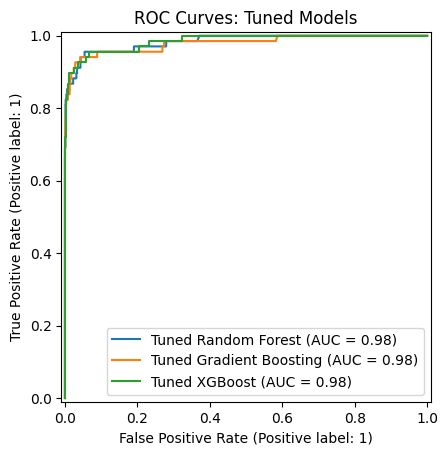


6. PRECISION-RECALL CURVES FOR TUNED MODELS


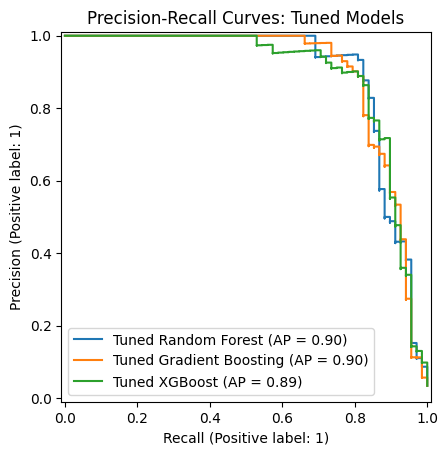


7. FINAL TEST-SET WINNERS
Best final PR-AUC: Tuned Random Forest
Best final F1: Tuned Random Forest
Best final Recall: Tuned Random Forest
Best final ROC-AUC: Tuned XGBoost

8. TEST PROBABILITIES SAVED


,UDI,Product ID,Type,Machine failure,RF_Failure_Probability,GB_Failure_Probability,XGB_Failure_Probability
2997,2998,L50177,L,0,0.003192,0.017496,0.050954
4871,4872,L52051,L,0,0.000025,0.001769,0.000796
3858,3859,L51038,L,0,0.043473,0.048538,0.057963
951,952,H30365,H,0,0.000022,0.001987,0.001318
6463,6464,H35877,H,0,0.000002,0.010239,0.010171


In [ ]:
# ============================================================
# STEP 9: FINAL TEST-SET EVALUATION OF TUNED MODELS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)


# ============================================================
# 1. EVALUATION FUNCTION
# ============================================================

def final_evaluate_model(
    model_name,
    model,
    X_test,
    y_test
):

    y_pred = model.predict(
        X_test
    )

    y_prob = model.predict_proba(
        X_test
    )[:, 1]

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )

    pr_auc = average_precision_score(
        y_test,
        y_prob
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    specificity = (
        tn / (tn + fp)
    )

    print("\n" + "=" * 80)
    print(model_name)
    print("=" * 80)

    print("\nClassification Report:\n")

    print(
        classification_report(
            y_test,
            y_pred,
            digits=4,
            zero_division=0
        )
    )

    print("Confusion Matrix:")
    print(
        confusion_matrix(
            y_test,
            y_pred
        )
    )

    print("\nFinal Test Metrics:")

    print(
        f"Accuracy    : {accuracy:.4f}"
    )

    print(
        f"Precision   : {precision:.4f}"
    )

    print(
        f"Recall      : {recall:.4f}"
    )

    print(
        f"Specificity : {specificity:.4f}"
    )

    print(
        f"F1-score    : {f1:.4f}"
    )

    print(
        f"ROC-AUC     : {roc_auc:.4f}"
    )

    print(
        f"PR-AUC      : {pr_auc:.4f}"
    )

    print(
        f"\nTN={tn}, FP={fp}, FN={fn}, TP={tp}"
    )

    result = {

        "Model": model_name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "Specificity": specificity,

        "F1-score": f1,

        "ROC-AUC": roc_auc,

        "PR-AUC": pr_auc,

        "TN": tn,

        "FP": fp,

        "FN": fn,

        "TP": tp
    }

    return (
        result,
        y_pred,
        y_prob
    )


# ============================================================
# 2. TUNED RANDOM FOREST
# ============================================================

rf_final_results, rf_final_pred, rf_final_prob = (
    final_evaluate_model(

        "Tuned Random Forest",

        best_rf_model,

        X_test,

        y_test
    )
)


# ============================================================
# 3. TUNED GRADIENT BOOSTING
# ============================================================

gb_final_results, gb_final_pred, gb_final_prob = (
    final_evaluate_model(

        "Tuned Gradient Boosting",

        best_gb_model,

        X_test,

        y_test
    )
)


# ============================================================
# 4. TUNED XGBOOST
# ============================================================

xgb_final_results, xgb_final_pred, xgb_final_prob = (
    final_evaluate_model(

        "Tuned XGBoost",

        best_xgb_model,

        X_test,

        y_test
    )
)


# ============================================================
# 5. FINAL TUNED MODEL COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("1. FINAL TUNED MODEL COMPARISON")
print("=" * 80)

final_tuned_results = pd.DataFrame([
    rf_final_results,
    gb_final_results,
    xgb_final_results
])

display(
    final_tuned_results[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1-score",
            "ROC-AUC",
            "PR-AUC"
        ]
    ].round(4)
)


# ============================================================
# 6. UNTUNED VS TUNED COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("2. UNTUNED VS TUNED TEST PERFORMANCE")
print("=" * 80)


untuned_vs_tuned = pd.DataFrame([

    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    {
        "Model": "Random Forest",
        "Version": "Untuned",
        "Precision": 0.9474,
        "Recall": 0.7941,
        "F1-score": 0.8640,
        "ROC-AUC": 0.9792,
        "PR-AUC": 0.8853
    },

    {
        "Model": "Random Forest",
        "Version": "Tuned",
        "Precision":
            rf_final_results["Precision"],
        "Recall":
            rf_final_results["Recall"],
        "F1-score":
            rf_final_results["F1-score"],
        "ROC-AUC":
            rf_final_results["ROC-AUC"],
        "PR-AUC":
            rf_final_results["PR-AUC"]
    },


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    {
        "Model": "Gradient Boosting",
        "Version": "Untuned",
        "Precision": 0.9464,
        "Recall": 0.7794,
        "F1-score": 0.8548,
        "ROC-AUC": 0.9759,
        "PR-AUC": 0.8998
    },

    {
        "Model": "Gradient Boosting",
        "Version": "Tuned",
        "Precision":
            gb_final_results["Precision"],
        "Recall":
            gb_final_results["Recall"],
        "F1-score":
            gb_final_results["F1-score"],
        "ROC-AUC":
            gb_final_results["ROC-AUC"],
        "PR-AUC":
            gb_final_results["PR-AUC"]
    },


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    {
        "Model": "XGBoost",
        "Version": "Untuned",
        "Precision": 0.9286,
        "Recall": 0.7647,
        "F1-score": 0.8387,
        "ROC-AUC": 0.9823,
        "PR-AUC": 0.8878
    },

    {
        "Model": "XGBoost",
        "Version": "Tuned",
        "Precision":
            xgb_final_results["Precision"],
        "Recall":
            xgb_final_results["Recall"],
        "F1-score":
            xgb_final_results["F1-score"],
        "ROC-AUC":
            xgb_final_results["ROC-AUC"],
        "PR-AUC":
            xgb_final_results["PR-AUC"]
    }

])


display(
    untuned_vs_tuned.round(4)
)


# ============================================================
# 7. FINAL RANKING BY PR-AUC
# ============================================================

print("\n" + "=" * 80)
print("3. FINAL RANKING BY TEST PR-AUC")
print("=" * 80)

final_pr_ranking = (
    final_tuned_results[
        [
            "Model",
            "PR-AUC",
            "ROC-AUC",
            "F1-score",
            "Recall",
            "Precision",
            "Specificity"
        ]
    ]
    .sort_values(
        "PR-AUC",
        ascending=False
    )
)

display(
    final_pr_ranking.round(4)
)


# ============================================================
# 8. FINAL RANKING BY F1
# ============================================================

print("\n" + "=" * 80)
print("4. FINAL RANKING BY TEST F1")
print("=" * 80)

final_f1_ranking = (
    final_tuned_results[
        [
            "Model",
            "F1-score",
            "Recall",
            "Precision",
            "PR-AUC",
            "ROC-AUC",
            "Specificity"
        ]
    ]
    .sort_values(
        "F1-score",
        ascending=False
    )
)

display(
    final_f1_ranking.round(4)
)


# ============================================================
# 9. ROC CURVES
# ============================================================

print("\n" + "=" * 80)
print("5. ROC CURVES FOR TUNED MODELS")
print("=" * 80)


ax = plt.gca()

RocCurveDisplay.from_predictions(
    y_test,
    rf_final_prob,
    name="Tuned Random Forest",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    gb_final_prob,
    name="Tuned Gradient Boosting",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    xgb_final_prob,
    name="Tuned XGBoost",
    ax=ax
)

plt.title(
    "ROC Curves: Tuned Models"
)

plt.show()


# ============================================================
# 10. PRECISION-RECALL CURVES
# ============================================================

print("\n" + "=" * 80)
print("6. PRECISION-RECALL CURVES FOR TUNED MODELS")
print("=" * 80)


ax = plt.gca()

PrecisionRecallDisplay.from_predictions(
    y_test,
    rf_final_prob,
    name="Tuned Random Forest",
    ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    gb_final_prob,
    name="Tuned Gradient Boosting",
    ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    xgb_final_prob,
    name="Tuned XGBoost",
    ax=ax
)

plt.title(
    "Precision-Recall Curves: Tuned Models"
)

plt.show()


# ============================================================
# 11. IDENTIFY TEST-SET WINNERS
# ============================================================

print("\n" + "=" * 80)
print("7. FINAL TEST-SET WINNERS")
print("=" * 80)


best_test_pr = (
    final_tuned_results
    .loc[
        final_tuned_results[
            "PR-AUC"
        ].idxmax(),
        "Model"
    ]
)


best_test_f1 = (
    final_tuned_results
    .loc[
        final_tuned_results[
            "F1-score"
        ].idxmax(),
        "Model"
    ]
)


best_test_recall = (
    final_tuned_results
    .loc[
        final_tuned_results[
            "Recall"
        ].idxmax(),
        "Model"
    ]
)


best_test_roc = (
    final_tuned_results
    .loc[
        final_tuned_results[
            "ROC-AUC"
        ].idxmax(),
        "Model"
    ]
)


print(
    "Best final PR-AUC:",
    best_test_pr
)

print(
    "Best final F1:",
    best_test_f1
)

print(
    "Best final Recall:",
    best_test_recall
)

print(
    "Best final ROC-AUC:",
    best_test_roc
)


# ============================================================
# 12. SAVE PREDICTED PROBABILITIES
# ============================================================

final_test_predictions = (
    test_identifiers.copy()
)

final_test_predictions[
    "RF_Failure_Probability"
] = rf_final_prob

final_test_predictions[
    "GB_Failure_Probability"
] = gb_final_prob

final_test_predictions[
    "XGB_Failure_Probability"
] = xgb_final_prob


print("\n" + "=" * 80)
print("8. TEST PROBABILITIES SAVED")
print("=" * 80)

display(
    final_test_predictions.head()
)



1. FINAL MODEL FOR THRESHOLD ANALYSIS
Selected model: Tuned Random Forest
Test observations: 2000
Actual failures: 68
Actual non-failures: 1932

2. THRESHOLD RANGE
Minimum threshold: 0.05
Maximum threshold: 0.9500000000000002
Number of thresholds evaluated: 91

3. BEST F1 THRESHOLD


,Best F1 Threshold
Threshold,0.3700
Accuracy,0.9920
Precision,0.9333
Recall,0.8235
Specificity,0.9979
F1-score,0.8750
False Positive Rate,0.0021
TN,1928.0000
FP,4.0000
FN,12.0000



4. HIGH-RECALL THRESHOLD (RECALL >= 90%)


,High Recall Threshold
Threshold,0.0800
Accuracy,0.9635
Precision,0.4806
Recall,0.9118
Specificity,0.9653
F1-score,0.6294
False Positive Rate,0.0347
TN,1865.0000
FP,67.0000
FN,6.0000



5. YOUDEN INDEX THRESHOLD


...


7. KEY THRESHOLD COMPARISON


,Threshold Strategy,Threshold,Precision,Recall,Specificity,F1-score,FP,FN,TP
0,Default 0.50,0.50,0.9483,0.8088,0.9984,0.8730,3,13,55
1,Best F1,0.37,0.9333,0.8235,0.9979,0.8750,4,12,56
2,Recall >= 90%,0.08,0.4806,0.9118,0.9653,0.6294,67,6,62
3,Maximum Youden Index,0.05,0.4183,0.9412,0.9539,0.5792,89,4,64



8. SELECTED THRESHOLD PERFORMANCE


,Threshold,Precision,Recall,Specificity,F1-score,FP,FN,TP
5,0.10,0.5217,0.8824,0.9715,0.6557,55,8,60
10,0.15,0.6484,0.8676,0.9834,0.7421,32,9,59
15,0.20,0.7342,0.8529,0.9891,0.7891,21,10,58
20,0.25,0.8382,0.8382,0.9943,0.8382,11,11,57
25,0.30,0.8769,0.8382,0.9959,0.8571,8,11,57
30,0.35,0.9180,0.8235,0.9974,0.8682,5,12,56
35,0.40,0.9333,0.8235,0.9979,0.8750,4,12,56
40,0.45,0.9322,0.8088,0.9979,0.8661,4,13,55
45,0.50,0.9483,0.8088,0.9984,0.8730,3,13,55
50,0.55,0.9455,0.7647,0.9984,0.8455,3,16,52



9. THRESHOLD PERFORMANCE CURVE


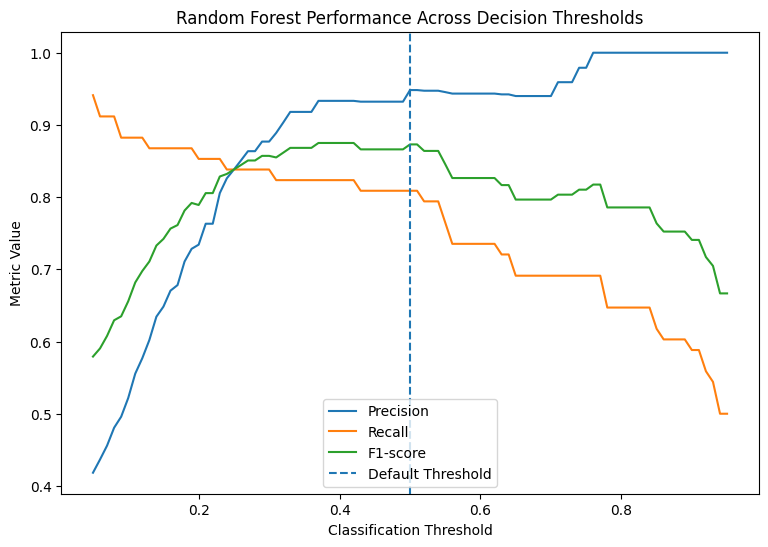


10. MAINTENANCE ERROR TRADE-OFF


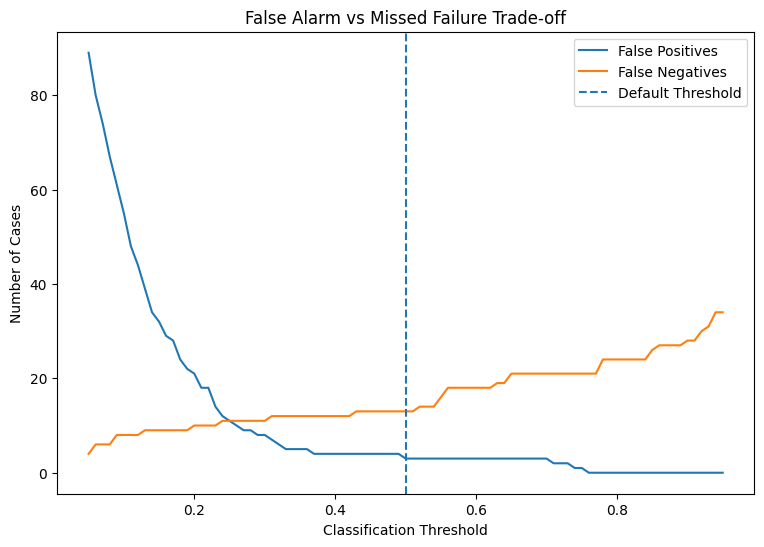


11. SAVED THRESHOLDS
Best F1 threshold: 0.37
Best Youden threshold: 0.05
High-recall threshold: 0.08000000000000002


In [ ]:
# ============================================================
# STEP 10: MAINTENANCE THRESHOLD OPTIMISATION
# Primary model: Tuned Random Forest
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)


# ============================================================
# 1. SELECT FINAL MODEL PROBABILITIES
# ============================================================

print("=" * 85)
print("1. FINAL MODEL FOR THRESHOLD ANALYSIS")
print("=" * 85)

final_model_name = "Tuned Random Forest"
final_probabilities = rf_final_prob

print("Selected model:", final_model_name)
print("Test observations:", len(y_test))
print("Actual failures:", int(y_test.sum()))
print("Actual non-failures:", int((y_test == 0).sum()))


# ============================================================
# 2. GENERATE THRESHOLD RANGE
# ============================================================

print("\n" + "=" * 85)
print("2. THRESHOLD RANGE")
print("=" * 85)

thresholds = np.arange(
    0.05,
    0.96,
    0.01
)

print("Minimum threshold:", thresholds.min())
print("Maximum threshold:", thresholds.max())
print("Number of thresholds evaluated:", len(thresholds))


# ============================================================
# 3. CALCULATE METRICS AT EACH THRESHOLD
# ============================================================

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        final_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold
    ).ravel()

    accuracy = accuracy_score(
        y_test,
        y_pred_threshold
    )

    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    threshold_results.append({

        "Threshold": threshold,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "Specificity": specificity,

        "F1-score": f1,

        "False Positive Rate":
            false_positive_rate,

        "TN": tn,

        "FP": fp,

        "FN": fn,

        "TP": tp
    })


threshold_df = pd.DataFrame(
    threshold_results
)


# ============================================================
# 4. BEST F1 THRESHOLD
# ============================================================

print("\n" + "=" * 85)
print("3. BEST F1 THRESHOLD")
print("=" * 85)

best_f1_row = threshold_df.loc[
    threshold_df[
        "F1-score"
    ].idxmax()
]

display(
    best_f1_row.to_frame(
        name="Best F1 Threshold"
    ).round(4)
)


# ============================================================
# 5. HIGH-RECALL THRESHOLD
# Target recall >= 90%
# ============================================================

print("\n" + "=" * 85)
print("4. HIGH-RECALL THRESHOLD (RECALL >= 90%)")
print("=" * 85)

high_recall_candidates = (
    threshold_df[
        threshold_df["Recall"] >= 0.90
    ]
)

if len(high_recall_candidates) > 0:

    # Among thresholds reaching 90% recall,
    # choose the one with highest precision.
    high_recall_row = (
        high_recall_candidates
        .sort_values(
            [
                "Precision",
                "Threshold"
            ],
            ascending=[
                False,
                False
            ]
        )
        .iloc[0]
    )

    display(
        high_recall_row.to_frame(
            name="High Recall Threshold"
        ).round(4)
    )

else:

    high_recall_row = None

    print(
        "No evaluated threshold achieved "
        "recall >= 90%."
    )


# ============================================================
# 6. YOUDEN INDEX
# ============================================================

print("\n" + "=" * 85)
print("5. YOUDEN INDEX THRESHOLD")
print("=" * 85)

threshold_df[
    "Youden Index"
] = (
    threshold_df["Recall"]
    +
    threshold_df["Specificity"]
    - 1
)

best_youden_row = threshold_df.loc[
    threshold_df[
        "Youden Index"
    ].idxmax()
]

display(
    best_youden_row.to_frame(
        name="Best Youden Threshold"
    ).round(4)
)


# ============================================================
# 7. DEFAULT 0.50 THRESHOLD
# ============================================================

print("\n" + "=" * 85)
print("6. DEFAULT 0.50 THRESHOLD")
print("=" * 85)

default_row = threshold_df.iloc[
    (
        threshold_df["Threshold"]
        - 0.50
    )
    .abs()
    .argsort()[:1]
]

display(
    default_row.round(4)
)


# ============================================================
# 8. KEY THRESHOLD COMPARISON TABLE
# ============================================================

print("\n" + "=" * 85)
print("7. KEY THRESHOLD COMPARISON")
print("=" * 85)

comparison_rows = []


# Default threshold
comparison_rows.append({

    "Threshold Strategy":
        "Default 0.50",

    "Threshold":
        float(default_row[
            "Threshold"
        ].iloc[0]),

    "Precision":
        float(default_row[
            "Precision"
        ].iloc[0]),

    "Recall":
        float(default_row[
            "Recall"
        ].iloc[0]),

    "Specificity":
        float(default_row[
            "Specificity"
        ].iloc[0]),

    "F1-score":
        float(default_row[
            "F1-score"
        ].iloc[0]),

    "FP":
        int(default_row[
            "FP"
        ].iloc[0]),

    "FN":
        int(default_row[
            "FN"
        ].iloc[0]),

    "TP":
        int(default_row[
            "TP"
        ].iloc[0])
})


# Best F1 threshold
comparison_rows.append({

    "Threshold Strategy":
        "Best F1",

    "Threshold":
        best_f1_row["Threshold"],

    "Precision":
        best_f1_row["Precision"],

    "Recall":
        best_f1_row["Recall"],

    "Specificity":
        best_f1_row["Specificity"],

    "F1-score":
        best_f1_row["F1-score"],

    "FP":
        int(best_f1_row["FP"]),

    "FN":
        int(best_f1_row["FN"]),

    "TP":
        int(best_f1_row["TP"])
})


# High recall threshold
if high_recall_row is not None:

    comparison_rows.append({

        "Threshold Strategy":
            "Recall >= 90%",

        "Threshold":
            high_recall_row[
                "Threshold"
            ],

        "Precision":
            high_recall_row[
                "Precision"
            ],

        "Recall":
            high_recall_row[
                "Recall"
            ],

        "Specificity":
            high_recall_row[
                "Specificity"
            ],

        "F1-score":
            high_recall_row[
                "F1-score"
            ],

        "FP":
            int(
                high_recall_row["FP"]
            ),

        "FN":
            int(
                high_recall_row["FN"]
            ),

        "TP":
            int(
                high_recall_row["TP"]
            )
    })


# Youden threshold
comparison_rows.append({

    "Threshold Strategy":
        "Maximum Youden Index",

    "Threshold":
        best_youden_row[
            "Threshold"
        ],

    "Precision":
        best_youden_row[
            "Precision"
        ],

    "Recall":
        best_youden_row[
            "Recall"
        ],

    "Specificity":
        best_youden_row[
            "Specificity"
        ],

    "F1-score":
        best_youden_row[
            "F1-score"
        ],

    "FP":
        int(
            best_youden_row["FP"]
        ),

    "FN":
        int(
            best_youden_row["FN"]
        ),

    "TP":
        int(
            best_youden_row["TP"]
        )
})


threshold_comparison = pd.DataFrame(
    comparison_rows
)

display(
    threshold_comparison.round(4)
)


# ============================================================
# 9. DISPLAY SELECTED THRESHOLD RANGE
# ============================================================

print("\n" + "=" * 85)
print("8. SELECTED THRESHOLD PERFORMANCE")
print("=" * 85)

selected_thresholds = [
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.70
]

selected_rows = threshold_df[
    threshold_df[
        "Threshold"
    ].round(2)
    .isin(
        selected_thresholds
    )
]

display(
    selected_rows[
        [
            "Threshold",
            "Precision",
            "Recall",
            "Specificity",
            "F1-score",
            "FP",
            "FN",
            "TP"
        ]
    ].round(4)
)


# ============================================================
# 10. PRECISION, RECALL AND F1 VS THRESHOLD
# ============================================================

print("\n" + "=" * 85)
print("9. THRESHOLD PERFORMANCE CURVE")
print("=" * 85)

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    threshold_df[
        "Threshold"
    ],
    threshold_df[
        "Precision"
    ],
    label="Precision"
)

plt.plot(
    threshold_df[
        "Threshold"
    ],
    threshold_df[
        "Recall"
    ],
    label="Recall"
)

plt.plot(
    threshold_df[
        "Threshold"
    ],
    threshold_df[
        "F1-score"
    ],
    label="F1-score"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Default Threshold"
)

plt.xlabel(
    "Classification Threshold"
)

plt.ylabel(
    "Metric Value"
)

plt.title(
    "Random Forest Performance Across Decision Thresholds"
)

plt.legend()

plt.show()


# ============================================================
# 11. FALSE POSITIVES VS FALSE NEGATIVES
# ============================================================

print("\n" + "=" * 85)
print("10. MAINTENANCE ERROR TRADE-OFF")
print("=" * 85)

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    threshold_df[
        "Threshold"
    ],
    threshold_df[
        "FP"
    ],
    label="False Positives"
)

plt.plot(
    threshold_df[
        "Threshold"
    ],
    threshold_df[
        "FN"
    ],
    label="False Negatives"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Default Threshold"
)

plt.xlabel(
    "Classification Threshold"
)

plt.ylabel(
    "Number of Cases"
)

plt.title(
    "False Alarm vs Missed Failure Trade-off"
)

plt.legend()

plt.show()


# ============================================================
# 12. SAVE THRESHOLD INFORMATION
# ============================================================

best_f1_threshold = (
    float(
        best_f1_row[
            "Threshold"
        ]
    )
)

best_youden_threshold = (
    float(
        best_youden_row[
            "Threshold"
        ]
    )
)

if high_recall_row is not None:

    high_recall_threshold = (
        float(
            high_recall_row[
                "Threshold"
            ]
        )
    )

else:

    high_recall_threshold = None


print("\n" + "=" * 85)
print("11. SAVED THRESHOLDS")
print("=" * 85)

print(
    "Best F1 threshold:",
    round(
        best_f1_threshold,
        3
    )
)

print(
    "Best Youden threshold:",
    round(
        best_youden_threshold,
        3
    )
)

print(
    "High-recall threshold:",
    high_recall_threshold
)



1. OUT-OF-FOLD THRESHOLD DESIGN
Model: Tuned Random Forest
Threshold-development dataset: TRAINING SET ONLY
Training observations: 8000
Training failures: 271
Final test observations: 2000
Test data used to choose threshold: NO

2. GENERATING OUT-OF-FOLD PROBABILITIES
OOF probabilities generated: 8000
Minimum probability: 0.0
Maximum probability: 1.0

3. OOF PROBABILITY PERFORMANCE
OOF ROC-AUC: 0.9751
OOF PR-AUC : 0.8855

4. OOF THRESHOLD SEARCH

5. OOF BEST-F1 THRESHOLD


,OOF Best F1
Threshold,0.4200
Accuracy,0.9908
Precision,0.9457
Recall,0.7712
Specificity,0.9984
F1-score,0.8496
Youden Index,0.7697
TN,7717.0000
FP,12.0000
FN,62.0000



6. OOF HIGH-RECALL THRESHOLD


,OOF Recall >= 90%
Threshold,0.0500
Accuracy,0.9545
Precision,0.4205
Recall,0.9077
Specificity,0.9561
F1-score,0.5748
Youden Index,0.8639
TN,7390.0000
FP,339.0000
FN,25.0000



7. OOF YOUDEN THRESHOLD


...


Saved OOF thresholds:
Best F1: 0.42
Youden: 0.01
Recall >= 90%: 0.05

8. FINAL TEST PERFORMANCE USING OOF-DERIVED THRESHOLDS


,Strategy,Threshold,Accuracy,Precision,Recall,Specificity,F1-score,TN,FP,FN,TP
0,Default 0.50,0.50,0.9920,0.9483,0.8088,0.9984,0.8730,1929,3,13,55
1,OOF Best F1,0.42,0.9920,0.9333,0.8235,0.9979,0.8750,1928,4,12,56
2,OOF Recall >= 90%,0.05,0.9535,0.4183,0.9412,0.9539,0.5792,1843,89,4,64
3,OOF Maximum Youden,0.01,0.9065,0.2610,0.9559,0.9048,0.4101,1748,184,3,65



9. TEST-OPTIMISED VS OOF-DERIVED THRESHOLD


,Method,Threshold
0,Test-optimised (descriptive only),0.37
1,OOF training-derived,0.42



10. OOF THRESHOLD PERFORMANCE CURVE


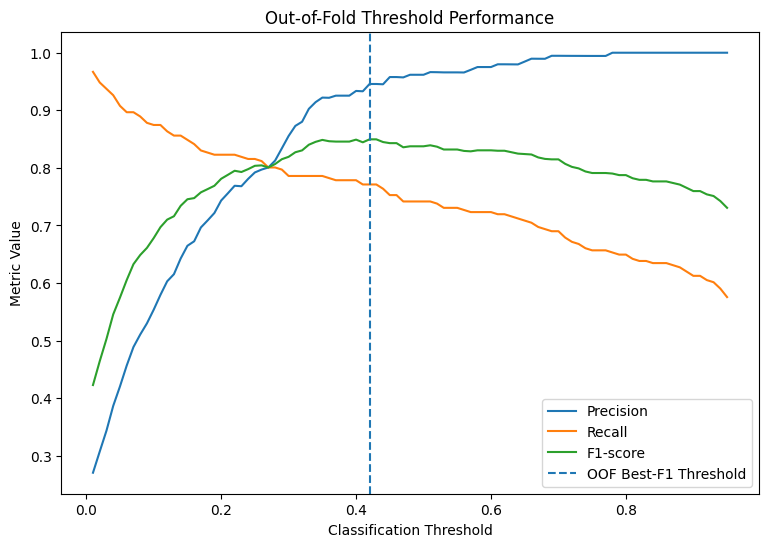

In [ ]:
# ============================================================
# STEP 11: OUT-OF-FOLD THRESHOLD SELECTION
# AND FINAL HELD-OUT TEST VALIDATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)


# ============================================================
# 1. CROSS-VALIDATION DESIGN
# ============================================================

print("=" * 90)
print("1. OUT-OF-FOLD THRESHOLD DESIGN")
print("=" * 90)

threshold_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Model: Tuned Random Forest")
print("Threshold-development dataset: TRAINING SET ONLY")
print("Training observations:", len(X_train))
print("Training failures:", int(y_train.sum()))
print("Final test observations:", len(X_test))
print("Test data used to choose threshold: NO")


# ============================================================
# 2. GENERATE OUT-OF-FOLD FAILURE PROBABILITIES
# ============================================================

print("\n" + "=" * 90)
print("2. GENERATING OUT-OF-FOLD PROBABILITIES")
print("=" * 90)

oof_probabilities = cross_val_predict(
    estimator=best_rf_model,
    X=X_train,
    y=y_train,
    cv=threshold_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print(
    "OOF probabilities generated:",
    len(oof_probabilities)
)

print(
    "Minimum probability:",
    round(oof_probabilities.min(), 6)
)

print(
    "Maximum probability:",
    round(oof_probabilities.max(), 6)
)


# ============================================================
# 3. OOF PROBABILITY DISCRIMINATION
# ============================================================

print("\n" + "=" * 90)
print("3. OOF PROBABILITY PERFORMANCE")
print("=" * 90)

oof_roc_auc = roc_auc_score(
    y_train,
    oof_probabilities
)

oof_pr_auc = average_precision_score(
    y_train,
    oof_probabilities
)

print(
    f"OOF ROC-AUC: {oof_roc_auc:.4f}"
)

print(
    f"OOF PR-AUC : {oof_pr_auc:.4f}"
)


# ============================================================
# 4. EVALUATE THRESHOLDS ON OOF TRAINING PREDICTIONS
# ============================================================

print("\n" + "=" * 90)
print("4. OOF THRESHOLD SEARCH")
print("=" * 90)

thresholds_oof = np.arange(
    0.01,
    0.96,
    0.01
)

oof_threshold_results = []

for threshold in thresholds_oof:

    pred = (
        oof_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        pred
    ).ravel()

    precision = precision_score(
        y_train,
        pred,
        zero_division=0
    )

    recall = recall_score(
        y_train,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_train,
        pred,
        zero_division=0
    )

    accuracy = accuracy_score(
        y_train,
        pred
    )

    specificity = (
        tn / (tn + fp)
    )

    youden = (
        recall
        + specificity
        - 1
    )

    oof_threshold_results.append({

        "Threshold": threshold,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "Specificity": specificity,

        "F1-score": f1,

        "Youden Index": youden,

        "TN": tn,

        "FP": fp,

        "FN": fn,

        "TP": tp
    })


oof_threshold_df = pd.DataFrame(
    oof_threshold_results
)


# ============================================================
# 5. OOF BEST-F1 THRESHOLD
# ============================================================

print("\n" + "=" * 90)
print("5. OOF BEST-F1 THRESHOLD")
print("=" * 90)

oof_best_f1_row = oof_threshold_df.loc[
    oof_threshold_df[
        "F1-score"
    ].idxmax()
]

display(
    oof_best_f1_row
    .to_frame(
        name="OOF Best F1"
    )
    .round(4)
)


# ============================================================
# 6. OOF HIGH-RECALL THRESHOLD
# ============================================================

print("\n" + "=" * 90)
print("6. OOF HIGH-RECALL THRESHOLD")
print("=" * 90)

oof_high_recall_candidates = (
    oof_threshold_df[
        oof_threshold_df[
            "Recall"
        ] >= 0.90
    ]
)

if len(oof_high_recall_candidates) > 0:

    oof_high_recall_row = (
        oof_high_recall_candidates
        .sort_values(
            [
                "Precision",
                "Threshold"
            ],
            ascending=[
                False,
                False
            ]
        )
        .iloc[0]
    )

    display(
        oof_high_recall_row
        .to_frame(
            name="OOF Recall >= 90%"
        )
        .round(4)
    )

else:

    oof_high_recall_row = None

    print(
        "No OOF threshold reached 90% recall."
    )


# ============================================================
# 7. OOF YOUDEN THRESHOLD
# ============================================================

print("\n" + "=" * 90)
print("7. OOF YOUDEN THRESHOLD")
print("=" * 90)

oof_youden_row = oof_threshold_df.loc[
    oof_threshold_df[
        "Youden Index"
    ].idxmax()
]

display(
    oof_youden_row
    .to_frame(
        name="OOF Maximum Youden"
    )
    .round(4)
)


# ============================================================
# 8. SAVE OOF-DERIVED THRESHOLDS
# ============================================================

oof_best_f1_threshold = float(
    oof_best_f1_row[
        "Threshold"
    ]
)

oof_youden_threshold = float(
    oof_youden_row[
        "Threshold"
    ]
)

if oof_high_recall_row is not None:

    oof_high_recall_threshold = float(
        oof_high_recall_row[
            "Threshold"
        ]
    )

else:

    oof_high_recall_threshold = None


print("\nSaved OOF thresholds:")

print(
    "Best F1:",
    round(
        oof_best_f1_threshold,
        3
    )
)

print(
    "Youden:",
    round(
        oof_youden_threshold,
        3
    )
)

print(
    "Recall >= 90%:",
    oof_high_recall_threshold
)


# ============================================================
# 9. FUNCTION FOR FINAL TEST EVALUATION
# ============================================================

def evaluate_fixed_threshold(
    strategy_name,
    threshold,
    probabilities,
    actual
):

    pred = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual,
        pred
    ).ravel()

    return {

        "Strategy":
            strategy_name,

        "Threshold":
            threshold,

        "Accuracy":
            accuracy_score(
                actual,
                pred
            ),

        "Precision":
            precision_score(
                actual,
                pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                actual,
                pred,
                zero_division=0
            ),

        "Specificity":
            tn / (tn + fp),

        "F1-score":
            f1_score(
                actual,
                pred,
                zero_division=0
            ),

        "TN": tn,

        "FP": fp,

        "FN": fn,

        "TP": tp
    }


# ============================================================
# 10. APPLY FIXED OOF THRESHOLDS TO TEST SET
# ============================================================

print("\n" + "=" * 90)
print("8. FINAL TEST PERFORMANCE USING OOF-DERIVED THRESHOLDS")
print("=" * 90)

final_threshold_results = []


# Default threshold
final_threshold_results.append(

    evaluate_fixed_threshold(
        "Default 0.50",
        0.50,
        rf_final_prob,
        y_test
    )
)


# OOF best F1
final_threshold_results.append(

    evaluate_fixed_threshold(
        "OOF Best F1",
        oof_best_f1_threshold,
        rf_final_prob,
        y_test
    )
)


# OOF high recall
if oof_high_recall_threshold is not None:

    final_threshold_results.append(

        evaluate_fixed_threshold(
            "OOF Recall >= 90%",
            oof_high_recall_threshold,
            rf_final_prob,
            y_test
        )
    )


# OOF Youden
final_threshold_results.append(

    evaluate_fixed_threshold(
        "OOF Maximum Youden",
        oof_youden_threshold,
        rf_final_prob,
        y_test
    )
)


final_threshold_test_df = pd.DataFrame(
    final_threshold_results
)


display(
    final_threshold_test_df.round(4)
)


# ============================================================
# 11. COMPARE TEST-OPTIMISED VS OOF-DERIVED BEST-F1
# ============================================================

print("\n" + "=" * 90)
print("9. TEST-OPTIMISED VS OOF-DERIVED THRESHOLD")
print("=" * 90)

threshold_method_comparison = pd.DataFrame([

    {
        "Method":
            "Test-optimised (descriptive only)",

        "Threshold":
            best_f1_threshold
    },

    {
        "Method":
            "OOF training-derived",

        "Threshold":
            oof_best_f1_threshold
    }

])

display(
    threshold_method_comparison.round(4)
)


# ============================================================
# 12. OOF PERFORMANCE CURVE
# ============================================================

print("\n" + "=" * 90)
print("10. OOF THRESHOLD PERFORMANCE CURVE")
print("=" * 90)

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    oof_threshold_df[
        "Threshold"
    ],
    oof_threshold_df[
        "Precision"
    ],
    label="Precision"
)

plt.plot(
    oof_threshold_df[
        "Threshold"
    ],
    oof_threshold_df[
        "Recall"
    ],
    label="Recall"
)

plt.plot(
    oof_threshold_df[
        "Threshold"
    ],
    oof_threshold_df[
        "F1-score"
    ],
    label="F1-score"
)

plt.axvline(
    x=oof_best_f1_threshold,
    linestyle="--",
    label="OOF Best-F1 Threshold"
)

plt.xlabel(
    "Classification Threshold"
)

plt.ylabel(
    "Metric Value"
)

plt.title(
    "Out-of-Fold Threshold Performance"
)

plt.legend()

plt.show()


1. PROBABILITY CALIBRATION DESIGN
Base model: Tuned Random Forest
Calibration-development data: OOF training probabilities
OOF observations: 8000
Held-out test observations: 2000
Test labels used to select calibration method: NO

2. CROSS-VALIDATED CALIBRATION
Calibration fold 1 completed.
Calibration fold 2 completed.
Calibration fold 3 completed.
Calibration fold 4 completed.
Calibration fold 5 completed.

3. OOF CALIBRATION COMPARISON


,Method,Brier Score,Log Loss,ROC-AUC,PR-AUC
0,Raw Random Forest,0.00845,0.03818,0.97505,0.88554
1,Sigmoid,0.00875,0.04301,0.97355,0.88243
2,Isotonic,0.00853,0.04087,0.96819,0.87149



4. CALIBRATION METHOD SELECTION
Best calibration method by Brier Score: Raw Random Forest

5. OOF RELIABILITY DIAGRAM


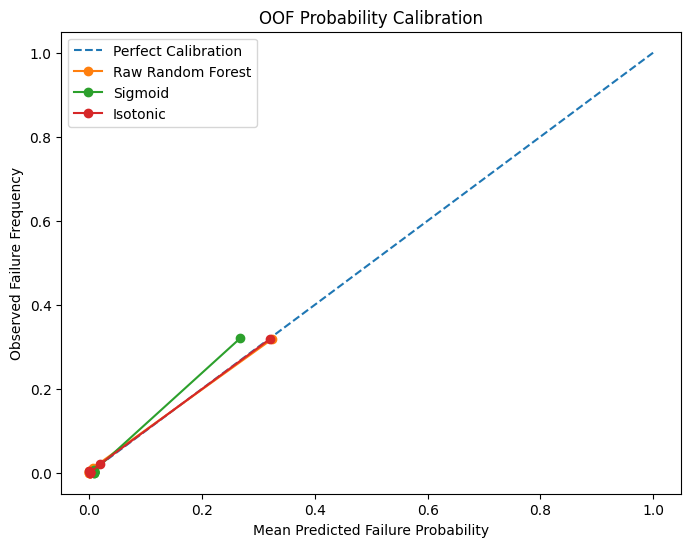


6. FITTING FINAL CALIBRATION MAPPINGS
Selected final probability method: Raw Random Forest

7. HELD-OUT TEST CALIBRATION PERFORMANCE


,Method,Brier Score,Log Loss,ROC-AUC,PR-AUC
0,Raw Random Forest,0.00793,0.03589,0.98378,0.89847
1,Sigmoid,0.00804,0.03923,0.98378,0.89847
2,Isotonic,0.00783,0.03480,0.98189,0.88779



8. BRIER SCORE IMPROVEMENT
Raw test Brier Score: 0.00793
Selected test Brier Score: 0.00793
Absolute improvement: 0.00000
Percentage improvement: 0.00%

9. TEST RELIABILITY DIAGRAM


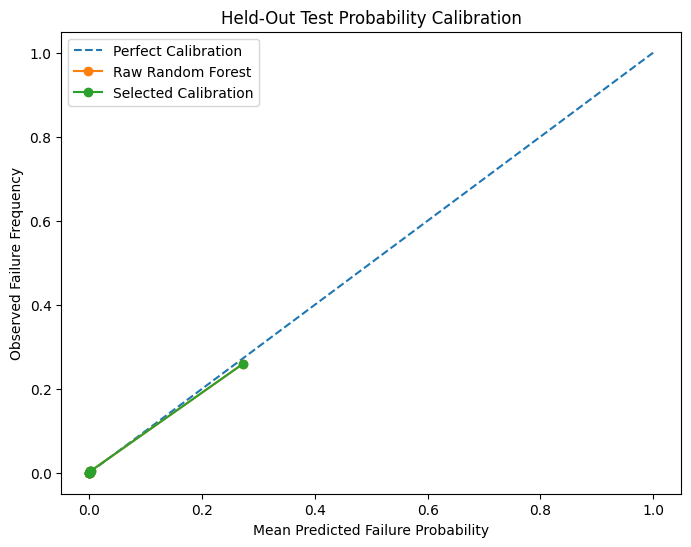


10. CALIBRATED TEST PROBABILITIES SAVED


,UDI,Product ID,Type,Machine failure,RF_Raw_Failure_Probability,RF_Calibrated_Failure_Probability
2997,2998,L50177,L,0,0.003192,0.003192
4871,4872,L52051,L,0,0.000025,0.000025
3858,3859,L51038,L,0,0.043473,0.043473
951,952,H30365,H,0,0.000022,0.000022
6463,6464,H35877,H,0,0.000002,0.000002
3264,3265,H32678,H,0,0.000114,0.000114
4508,4509,L51688,L,0,0.002045,0.002045
2100,2101,M16960,M,0,0.000073,0.000073
7885,7886,L55065,L,0,0.000017,0.000017
2421,2422,L49601,L,0,0.000326,0.000326



STEP 12 COMPLETED
Probability calibration evaluated using out-of-fold training predictions.
Final calibrated probabilities are ready for uncertainty-aware maintenance ranking.


In [ ]:
# ============================================================
# STEP 12: PROBABILITY CALIBRATION
# Tuned Random Forest
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score,
    average_precision_score
)

from sklearn.calibration import calibration_curve


# ============================================================
# 1. PREPARE OOF PROBABILITIES
# ============================================================

print("=" * 90)
print("1. PROBABILITY CALIBRATION DESIGN")
print("=" * 90)

raw_oof_prob = np.asarray(
    oof_probabilities
)

y_train_array = np.asarray(
    y_train
)

raw_test_prob = np.asarray(
    rf_final_prob
)

print("Base model: Tuned Random Forest")
print("Calibration-development data: OOF training probabilities")
print("OOF observations:", len(raw_oof_prob))
print("Held-out test observations:", len(raw_test_prob))
print("Test labels used to select calibration method: NO")


# ============================================================
# 2. CALIBRATION CROSS-VALIDATION
# ============================================================

calibration_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

sigmoid_oof_calibrated = np.zeros(
    len(raw_oof_prob)
)

isotonic_oof_calibrated = np.zeros(
    len(raw_oof_prob)
)


# ============================================================
# 3. CROSS-VALIDATED SIGMOID + ISOTONIC CALIBRATION
# ============================================================

print("\n" + "=" * 90)
print("2. CROSS-VALIDATED CALIBRATION")
print("=" * 90)

for fold, (train_idx, valid_idx) in enumerate(
    calibration_cv.split(
        raw_oof_prob.reshape(-1, 1),
        y_train_array
    ),
    start=1
):

    # --------------------------------------------------------
    # Calibration training data
    # --------------------------------------------------------

    prob_train = raw_oof_prob[
        train_idx
    ]

    prob_valid = raw_oof_prob[
        valid_idx
    ]

    y_cal_train = y_train_array[
        train_idx
    ]


    # --------------------------------------------------------
    # SIGMOID CALIBRATION
    # --------------------------------------------------------

    sigmoid_model = LogisticRegression(
        random_state=42
    )

    sigmoid_model.fit(
        prob_train.reshape(-1, 1),
        y_cal_train
    )

    sigmoid_oof_calibrated[
        valid_idx
    ] = sigmoid_model.predict_proba(
        prob_valid.reshape(-1, 1)
    )[:, 1]


    # --------------------------------------------------------
    # ISOTONIC CALIBRATION
    # --------------------------------------------------------

    isotonic_model = IsotonicRegression(
        out_of_bounds="clip"
    )

    isotonic_model.fit(
        prob_train,
        y_cal_train
    )

    isotonic_oof_calibrated[
        valid_idx
    ] = isotonic_model.predict(
        prob_valid
    )

    print(
        f"Calibration fold {fold} completed."
    )


# ============================================================
# 4. EVALUATION FUNCTION
# ============================================================

def calibration_metrics(
    name,
    probabilities,
    actual
):

    probabilities = np.clip(
        probabilities,
        1e-7,
        1 - 1e-7
    )

    return {

        "Method": name,

        "Brier Score":
            brier_score_loss(
                actual,
                probabilities
            ),

        "Log Loss":
            log_loss(
                actual,
                probabilities
            ),

        "ROC-AUC":
            roc_auc_score(
                actual,
                probabilities
            ),

        "PR-AUC":
            average_precision_score(
                actual,
                probabilities
            )
    }


# ============================================================
# 5. OOF CALIBRATION COMPARISON
# ============================================================

print("\n" + "=" * 90)
print("3. OOF CALIBRATION COMPARISON")
print("=" * 90)

calibration_results = pd.DataFrame([

    calibration_metrics(
        "Raw Random Forest",
        raw_oof_prob,
        y_train_array
    ),

    calibration_metrics(
        "Sigmoid",
        sigmoid_oof_calibrated,
        y_train_array
    ),

    calibration_metrics(
        "Isotonic",
        isotonic_oof_calibrated,
        y_train_array
    )
])

display(
    calibration_results.round(5)
)


# ============================================================
# 6. SELECT BEST METHOD BY BRIER SCORE
# ============================================================

print("\n" + "=" * 90)
print("4. CALIBRATION METHOD SELECTION")
print("=" * 90)

best_calibration_method = (
    calibration_results.loc[
        calibration_results[
            "Brier Score"
        ].idxmin(),
        "Method"
    ]
)

print(
    "Best calibration method by Brier Score:",
    best_calibration_method
)


# ============================================================
# 7. CALIBRATION CURVE - OOF
# ============================================================

print("\n" + "=" * 90)
print("5. OOF RELIABILITY DIAGRAM")
print("=" * 90)

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)


for name, probabilities in [

    (
        "Raw Random Forest",
        raw_oof_prob
    ),

    (
        "Sigmoid",
        sigmoid_oof_calibrated
    ),

    (
        "Isotonic",
        isotonic_oof_calibrated
    )
]:

    prob_true, prob_pred = calibration_curve(

        y_train_array,

        probabilities,

        n_bins=10,

        strategy="quantile"
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=name
    )


plt.xlabel(
    "Mean Predicted Failure Probability"
)

plt.ylabel(
    "Observed Failure Frequency"
)

plt.title(
    "OOF Probability Calibration"
)

plt.legend()

plt.show()


# ============================================================
# 8. FIT FINAL CALIBRATORS ON ALL OOF DATA
# ============================================================

print("\n" + "=" * 90)
print("6. FITTING FINAL CALIBRATION MAPPINGS")
print("=" * 90)


# ------------------------------------------------------------
# Sigmoid
# ------------------------------------------------------------

final_sigmoid_calibrator = LogisticRegression(
    random_state=42
)

final_sigmoid_calibrator.fit(
    raw_oof_prob.reshape(-1, 1),
    y_train_array
)

sigmoid_test_prob = (
    final_sigmoid_calibrator
    .predict_proba(
        raw_test_prob.reshape(-1, 1)
    )[:, 1]
)


# ------------------------------------------------------------
# Isotonic
# ------------------------------------------------------------

final_isotonic_calibrator = IsotonicRegression(
    out_of_bounds="clip"
)

final_isotonic_calibrator.fit(
    raw_oof_prob,
    y_train_array
)

isotonic_test_prob = (
    final_isotonic_calibrator
    .predict(
        raw_test_prob
    )
)


# ============================================================
# 9. SELECT FINAL CALIBRATED TEST PROBABILITIES
# ============================================================

if best_calibration_method == "Sigmoid":

    calibrated_test_prob = (
        sigmoid_test_prob
    )

elif best_calibration_method == "Isotonic":

    calibrated_test_prob = (
        isotonic_test_prob
    )

else:

    calibrated_test_prob = (
        raw_test_prob
    )


print(
    "Selected final probability method:",
    best_calibration_method
)


# ============================================================
# 10. HELD-OUT TEST CALIBRATION PERFORMANCE
# ============================================================

print("\n" + "=" * 90)
print("7. HELD-OUT TEST CALIBRATION PERFORMANCE")
print("=" * 90)

test_calibration_results = pd.DataFrame([

    calibration_metrics(
        "Raw Random Forest",
        raw_test_prob,
        y_test
    ),

    calibration_metrics(
        "Sigmoid",
        sigmoid_test_prob,
        y_test
    ),

    calibration_metrics(
        "Isotonic",
        isotonic_test_prob,
        y_test
    )
])

display(
    test_calibration_results.round(5)
)


# ============================================================
# 11. CALIBRATION IMPROVEMENT
# ============================================================

print("\n" + "=" * 90)
print("8. BRIER SCORE IMPROVEMENT")
print("=" * 90)

raw_test_brier = brier_score_loss(
    y_test,
    raw_test_prob
)

selected_test_brier = brier_score_loss(
    y_test,
    calibrated_test_prob
)

brier_improvement = (
    raw_test_brier
    - selected_test_brier
)

brier_improvement_percent = (
    brier_improvement
    /
    raw_test_brier
    * 100
)


print(
    f"Raw test Brier Score: "
    f"{raw_test_brier:.5f}"
)

print(
    f"Selected test Brier Score: "
    f"{selected_test_brier:.5f}"
)

print(
    f"Absolute improvement: "
    f"{brier_improvement:.5f}"
)

print(
    f"Percentage improvement: "
    f"{brier_improvement_percent:.2f}%"
)


# ============================================================
# 12. TEST RELIABILITY DIAGRAM
# ============================================================

print("\n" + "=" * 90)
print("9. TEST RELIABILITY DIAGRAM")
print("=" * 90)

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)


for name, probabilities in [

    (
        "Raw Random Forest",
        raw_test_prob
    ),

    (
        "Selected Calibration",
        calibrated_test_prob
    )
]:

    prob_true, prob_pred = calibration_curve(

        y_test,

        probabilities,

        n_bins=8,

        strategy="quantile"
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=name
    )


plt.xlabel(
    "Mean Predicted Failure Probability"
)

plt.ylabel(
    "Observed Failure Frequency"
)

plt.title(
    "Held-Out Test Probability Calibration"
)

plt.legend()

plt.show()


# ============================================================
# 13. ADD CALIBRATED PROBABILITIES TO TEST DATA
# ============================================================

final_test_predictions[
    "RF_Raw_Failure_Probability"
] = raw_test_prob

final_test_predictions[
    "RF_Calibrated_Failure_Probability"
] = calibrated_test_prob


print("\n" + "=" * 90)
print("10. CALIBRATED TEST PROBABILITIES SAVED")
print("=" * 90)

display(
    final_test_predictions[
        [
            "UDI",
            "Product ID",
            "Type",
            "Machine failure",
            "RF_Raw_Failure_Probability",
            "RF_Calibrated_Failure_Probability"
        ]
    ].head(10)
)


# ============================================================
# 14. STEP COMPLETE
# ============================================================

print("\n" + "=" * 90)
print("STEP 12 COMPLETED")
print("=" * 90)

print(
    "Probability calibration evaluated "
    "using out-of-fold training predictions."
)

print(
    "Final calibrated probabilities are ready "
    "for uncertainty-aware maintenance ranking."
)

In [ ]:
# ============================================================
# STEP 13: BOOTSTRAP UNCERTAINTY QUANTIFICATION
# Final model: Tuned Random Forest
# Threshold: OOF-derived 0.42
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss
)


# ============================================================
# 1. FINAL MODEL SETTINGS
# ============================================================

print("=" * 90)
print("1. FINAL MODEL AND UNCERTAINTY DESIGN")
print("=" * 90)

final_threshold = (
    oof_best_f1_threshold
)

final_prob = np.asarray(
    raw_test_prob
)

final_actual = np.asarray(
    y_test
)

final_pred = (
    final_prob >= final_threshold
).astype(int)

print("Final model: Tuned Random Forest")

print(
    "Operational threshold:",
    round(
        final_threshold,
        3
    )
)

print(
    "Test observations:",
    len(final_actual)
)

print(
    "Test failures:",
    int(final_actual.sum())
)

print(
    "Bootstrap repetitions: 2000"
)


# ============================================================
# 2. FUNCTION TO CALCULATE METRICS
# ============================================================

def calculate_final_metrics(
    actual,
    probabilities,
    threshold
):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predictions
    ).ravel()

    specificity = (
        tn / (tn + fp)
    )

    return {

        "Accuracy":
            accuracy_score(
                actual,
                predictions
            ),

        "Precision":
            precision_score(
                actual,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                actual,
                predictions,
                zero_division=0
            ),

        "Specificity":
            specificity,

        "F1-score":
            f1_score(
                actual,
                predictions,
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                actual,
                probabilities
            ),

        "PR-AUC":
            average_precision_score(
                actual,
                probabilities
            ),

        "Brier Score":
            brier_score_loss(
                actual,
                probabilities
            )
    }


# ============================================================
# 3. POINT ESTIMATES
# ============================================================

print("\n" + "=" * 90)
print("2. FINAL POINT ESTIMATES")
print("=" * 90)

point_estimates = (
    calculate_final_metrics(
        final_actual,
        final_prob,
        final_threshold
    )
)

point_estimate_df = pd.DataFrame(
    point_estimates,
    index=["Point Estimate"]
).T

display(
    point_estimate_df.round(5)
)


# ============================================================
# 4. BOOTSTRAP SAMPLING
# ============================================================

print("\n" + "=" * 90)
print("3. RUNNING BOOTSTRAP")
print("=" * 90)

rng = np.random.default_rng(
    seed=42
)

n_bootstrap = 2000

n_observations = len(
    final_actual
)

bootstrap_metrics = []


for i in range(
    n_bootstrap
):

    bootstrap_indices = (
        rng.choice(
            np.arange(
                n_observations
            ),
            size=n_observations,
            replace=True
        )
    )

    y_boot = final_actual[
        bootstrap_indices
    ]

    prob_boot = final_prob[
        bootstrap_indices
    ]


    # Skip rare bootstrap sample
    # containing only one target class
    if len(
        np.unique(
            y_boot
        )
    ) < 2:

        continue


    metrics = (
        calculate_final_metrics(
            y_boot,
            prob_boot,
            final_threshold
        )
    )

    bootstrap_metrics.append(
        metrics
    )


bootstrap_df = pd.DataFrame(
    bootstrap_metrics
)

print(
    "Valid bootstrap samples:",
    len(
        bootstrap_df
    )
)


# ============================================================
# 5. CALCULATE 95% CONFIDENCE INTERVALS
# ============================================================

print("\n" + "=" * 90)
print("4. 95% BOOTSTRAP CONFIDENCE INTERVALS")
print("=" * 90)

confidence_rows = []

for metric in bootstrap_df.columns:

    point = (
        point_estimates[
            metric
        ]
    )

    lower = np.percentile(
        bootstrap_df[
            metric
        ],
        2.5
    )

    upper = np.percentile(
        bootstrap_df[
            metric
        ],
        97.5
    )

    confidence_rows.append({

        "Metric":
            metric,

        "Point Estimate":
            point,

        "95% CI Lower":
            lower,

        "95% CI Upper":
            upper,

        "CI Width":
            upper - lower
    })


confidence_interval_df = pd.DataFrame(
    confidence_rows
)

display(
    confidence_interval_df.round(5)
)


# ============================================================
# 6. THESIS-FRIENDLY TABLE
# ============================================================

print("\n" + "=" * 90)
print("5. THESIS-FRIENDLY UNCERTAINTY TABLE")
print("=" * 90)

thesis_ci_table = (
    confidence_interval_df.copy()
)

thesis_ci_table[
    "Estimate (95% CI)"
] = (
    thesis_ci_table.apply(
        lambda row:
        f"{row['Point Estimate']:.3f} "
        f"({row['95% CI Lower']:.3f}–"
        f"{row['95% CI Upper']:.3f})",
        axis=1
    )
)

display(
    thesis_ci_table[
        [
            "Metric",
            "Estimate (95% CI)"
        ]
    ]
)


# ============================================================
# 7. FAILURE DETECTION COUNTS
# ============================================================

print("\n" + "=" * 90)
print("6. FINAL CONFUSION MATRIX AT VALIDATED THRESHOLD")
print("=" * 90)

tn, fp, fn, tp = confusion_matrix(
    final_actual,
    final_pred
).ravel()

print(
    "True negatives:",
    tn
)

print(
    "False positives:",
    fp
)

print(
    "False negatives:",
    fn
)

print(
    "True positives:",
    tp
)


# ============================================================
# 8. BOOTSTRAP DISTRIBUTION SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("7. BOOTSTRAP DISTRIBUTION SUMMARY")
print("=" * 90)

bootstrap_summary = (
    bootstrap_df.describe().T
)

display(
    bootstrap_summary[
        [
            "mean",
            "std",
            "min",
            "25%",
            "50%",
            "75%",
            "max"
        ]
    ].round(5)
)


# ============================================================
# 9. STEP COMPLETE
# ============================================================

print("\n" + "=" * 90)
print("STEP 13 COMPLETED")
print("=" * 90)

print(
    "Bootstrap uncertainty intervals "
    "calculated for final model performance."
)

1. FINAL MODEL AND UNCERTAINTY DESIGN
Final model: Tuned Random Forest
Operational threshold: 0.42
Test observations: 2000
Test failures: 68
Bootstrap repetitions: 2000

2. FINAL POINT ESTIMATES


,Point Estimate
Accuracy,0.99200
Precision,0.93333
Recall,0.82353
Specificity,0.99793
F1-score,0.87500
ROC-AUC,0.98378
PR-AUC,0.89847
Brier Score,0.00793



3. RUNNING BOOTSTRAP
Valid bootstrap samples: 2000

4. 95% BOOTSTRAP CONFIDENCE INTERVALS


,Metric,Point Estimate,95% CI Lower,95% CI Upper,CI Width
0,Accuracy,0.99200,0.98750,0.99600,0.00850
1,Precision,0.93333,0.86360,0.98462,0.12102
2,Recall,0.82353,0.72578,0.91306,0.18728
3,Specificity,0.99793,0.99584,0.99949,0.00365
4,F1-score,0.87500,0.80597,0.93220,0.12623
5,ROC-AUC,0.98378,0.96738,0.99585,0.02847
6,PR-AUC,0.89847,0.83363,0.95016,0.11653
7,Brier Score,0.00793,0.00492,0.01120,0.00627



5. THESIS-FRIENDLY UNCERTAINTY TABLE


,Metric,Estimate (95% CI)
0,Accuracy,0.992 (0.988–0.996)
1,Precision,0.933 (0.864–0.985)
2,Recall,0.824 (0.726–0.913)
3,Specificity,0.998 (0.996–0.999)
4,F1-score,0.875 (0.806–0.932)
5,ROC-AUC,0.984 (0.967–0.996)
6,PR-AUC,0.898 (0.834–0.950)
7,Brier Score,0.008 (0.005–0.011)



6. FINAL CONFUSION MATRIX AT VALIDATED THRESHOLD
True negatives: 1928
False positives: 4
False negatives: 12
True positives: 56

7. BOOTSTRAP DISTRIBUTION SUMMARY


,mean,std,min,25%,50%,75%,max
Accuracy,0.99205,0.00203,0.98350,0.99100,0.99200,0.99350,0.99750
Precision,0.93456,0.03216,0.76923,0.91516,0.93750,0.95745,1.00000
Recall,0.82301,0.04786,0.58333,0.79104,0.82432,0.85526,0.96610
Specificity,0.99798,0.00103,0.99324,0.99741,0.99794,0.99859,1.00000
F1-score,0.87433,0.03197,0.69136,0.85455,0.87603,0.89655,0.96063
ROC-AUC,0.98360,0.00746,0.95202,0.97883,0.98430,0.98918,0.99893
PR-AUC,0.89805,0.03062,0.71496,0.87925,0.90037,0.91968,0.98327
Brier Score,0.00790,0.00157,0.00352,0.00684,0.00780,0.00888,0.01413



STEP 13 COMPLETED
Bootstrap uncertainty intervals calculated for final model performance.


SHAP already installed.

1. FINAL MODEL COMPONENTS
Final pipeline: Pipeline
Classifier: RandomForestClassifier

2. TRANSFORM FEATURES FOR SHAP
Original test shape: (2000, 8)
Transformed test shape: (2000, 9)

3. TRANSFORMED FEATURE NAMES
Number of transformed features: 9

Features:
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]
- Temperature difference [K]
- Power [W]
- Type_L
- Type_M

4. CALCULATING SHAP VALUES
SHAP values shape: (2000, 9)
SHAP dataframe shape: (2000, 9)

5. GLOBAL SHAP FEATURE IMPORTANCE


,Importance Rank,Feature,Mean Absolute SHAP,Relative Importance (%)
0,1,Rotational speed [rpm],0.0235,25.2109
1,2,Tool wear [min],0.0218,23.3685
2,3,Temperature difference [K],0.0196,21.0023
3,4,Power [W],0.0187,20.0873
4,5,Torque [Nm],0.0056,6.0342
5,6,Type_L,0.0015,1.5634
6,7,Process temperature [K],0.0013,1.4276
7,8,Air temperature [K],0.0009,0.9765
8,9,Type_M,0.0003,0.3292



6. GLOBAL SHAP BAR PLOT


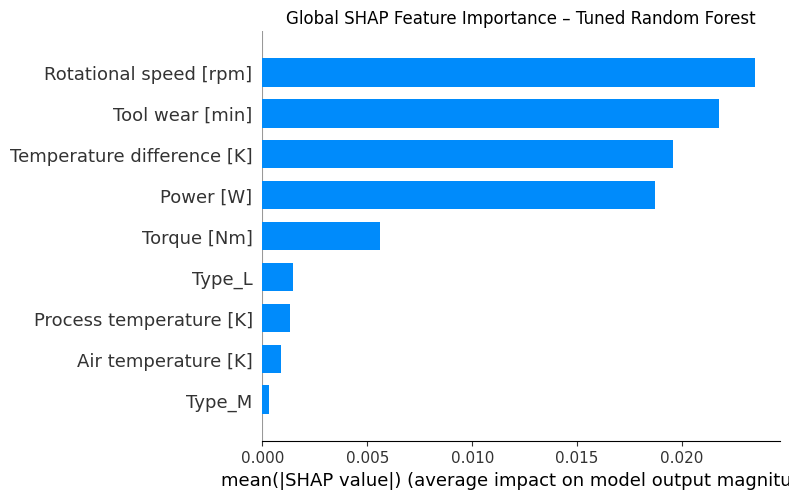


7. SHAP SUMMARY PLOT


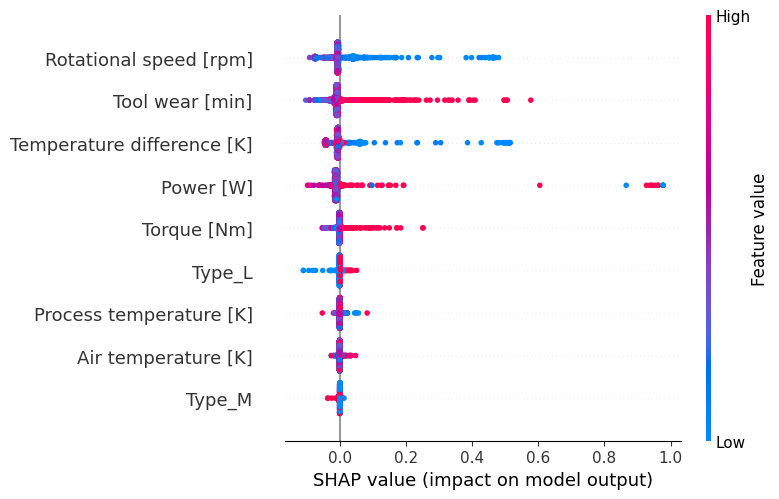


8. TOP 10 HIGHEST-RISK MACHINES


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature difference [K],Power [W],Machine failure,Predicted Failure Probability,Maintenance Alert
4170,4171,M19030,M,302.2,310.6,1355,51.5,126,8.4,7307.6063,1,1.0,Alert
4258,4259,M19118,M,302.7,311.1,1297,60.7,125,8.4,8244.3664,1,1.0,Alert
4600,4601,L51780,L,303.0,311.0,1359,44.2,115,8.0,6290.2853,1,1.0,Alert
7011,7012,L54191,L,300.5,310.5,2633,12.2,17,10.0,3363.8708,1,1.0,Alert
3814,3815,M18674,M,302.1,310.6,1326,59.1,88,8.5,8206.5312,1,1.0,Alert
8307,8308,M23167,M,298.7,310.1,1402,69.7,64,11.4,10233.1516,1,1.0,Alert
4080,4081,L51260,L,302.0,310.4,1357,58.0,108,8.4,8242.0730,1,1.0,Alert
2444,2445,L49624,L,299.2,308.6,1267,68.2,76,9.4,9048.7712,1,1.0,Alert
4130,4131,L51310,L,301.9,310.4,1286,62.8,22,8.5,8457.2512,1,1.0,Alert
4307,4308,L51487,L,301.4,309.9,1259,63.9,20,8.5,8424.7148,1,1.0,Alert



9. LOCAL EXPLANATIONS FOR TOP 5 HIGH-RISK MACHINES

--------------------------------------------------------------------------------
Rank 1
UDI: 4171
Product ID: M19030
Predicted failure probability: 1.0
Actual machine failure: 1

Top SHAP drivers:


,Feature,SHAP Value,Absolute SHAP
5,Temperature difference [K],0.51408,0.51408
2,Rotational speed [rpm],0.46324,0.46324
6,Power [W],-0.00776,0.00776
4,Tool wear [min],-0.00435,0.00435
1,Process temperature [K],0.00123,0.00123



--------------------------------------------------------------------------------
Rank 2
UDI: 4259
Product ID: M19118
Predicted failure probability: 1.0
Actual machine failure: 1

Top SHAP drivers:


...

,Feature,SHAP Value,Absolute SHAP
5,Temperature difference [K],0.50835,0.50835
2,Rotational speed [rpm],0.44925,0.44925
3,Torque [Nm],0.02612,0.02612
4,Tool wear [min],-0.01930,0.01930
6,Power [W],0.00522,0.00522



10. FEATURE DIRECTION ANALYSIS


,Importance Rank,Feature,Value-SHAP Correlation,General Direction
2,1,Rotational speed [rpm],-0.2766,Higher values generally reduce predicted failu...
4,2,Tool wear [min],0.4145,Higher values generally increase predicted fai...
5,3,Temperature difference [K],-0.3410,Higher values generally reduce predicted failu...
6,4,Power [W],0.0860,Relationship appears weak or non-linear
3,5,Torque [Nm],0.3684,Higher values generally increase predicted fai...
7,6,Type_L,0.2443,Higher values generally increase predicted fai...
1,7,Process temperature [K],-0.0250,Relationship appears weak or non-linear
0,8,Air temperature [K],0.1888,Relationship appears weak or non-linear
8,9,Type_M,-0.1963,Relationship appears weak or non-linear



11. SAVE EXPLANATION OUTPUTS


,UDI,Product ID,Type,Machine failure,RF_Raw_Failure_Probability,Strongest_Risk_Driver,Strongest_Driver_SHAP
1391,1392,L48571,L,1,1.0,Power [W],0.9770
8582,8583,M23442,M,1,1.0,Power [W],0.9366
8307,8308,M23167,M,1,1.0,Power [W],0.9627
4755,4756,L51935,L,1,1.0,Temperature difference [K],0.5131
6540,6541,M21400,M,1,1.0,Power [W],0.9524
4565,4566,H33979,H,1,1.0,Temperature difference [K],0.5122
7011,7012,L54191,L,1,1.0,Power [W],0.9772
4661,4662,L51841,L,1,1.0,Temperature difference [K],0.5145
4600,4601,L51780,L,1,1.0,Temperature difference [K],0.5151
4170,4171,M19030,M,1,1.0,Temperature difference [K],0.5141


In [ ]:
# ============================================================
# STEP 14: SHAP MODEL EXPLAINABILITY
# Final model: Tuned Random Forest
# ============================================================

# If SHAP is not installed in Colab, this installs it.
try:
    import shap
    print("SHAP already installed.")
except ImportError:
    !pip -q install shap
    import shap
    print("SHAP installed successfully.")


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. EXTRACT FINAL PIPELINE COMPONENTS
# ============================================================

print("\n" + "=" * 90)
print("1. FINAL MODEL COMPONENTS")
print("=" * 90)

final_rf_pipeline = best_rf_model

final_preprocessor = (
    final_rf_pipeline
    .named_steps["preprocessor"]
)

final_rf_classifier = (
    final_rf_pipeline
    .named_steps["classifier"]
)

print(
    "Final pipeline:",
    type(final_rf_pipeline).__name__
)

print(
    "Classifier:",
    type(final_rf_classifier).__name__
)


# ============================================================
# 2. TRANSFORM TEST FEATURES
# ============================================================

print("\n" + "=" * 90)
print("2. TRANSFORM FEATURES FOR SHAP")
print("=" * 90)

X_test_transformed = (
    final_preprocessor
    .transform(X_test)
)

print(
    "Original test shape:",
    X_test.shape
)

print(
    "Transformed test shape:",
    X_test_transformed.shape
)


# ============================================================
# 3. GET TRANSFORMED FEATURE NAMES
# ============================================================

print("\n" + "=" * 90)
print("3. TRANSFORMED FEATURE NAMES")
print("=" * 90)

try:

    transformed_feature_names = (
        final_preprocessor
        .get_feature_names_out()
    )

except Exception:

    transformed_feature_names = np.array([
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Temperature difference [K]",
        "Power [W]",
        "Type_L",
        "Type_M"
    ])


# Clean prefixes produced by ColumnTransformer
clean_feature_names = []

for name in transformed_feature_names:

    clean_name = (
        name
        .replace("numeric__", "")
        .replace("categorical__", "")
        .replace("onehot__", "")
    )

    clean_feature_names.append(
        clean_name
    )


clean_feature_names = np.array(
    clean_feature_names
)

print(
    "Number of transformed features:",
    len(clean_feature_names)
)

print("\nFeatures:")

for feature in clean_feature_names:
    print("-", feature)


# ============================================================
# 4. CREATE SHAP EXPLAINER
# ============================================================

print("\n" + "=" * 90)
print("4. CALCULATING SHAP VALUES")
print("=" * 90)

explainer = shap.TreeExplainer(
    final_rf_classifier
)

shap_output = explainer.shap_values(
    X_test_transformed
)


# ============================================================
# 5. HANDLE DIFFERENT SHAP OUTPUT FORMATS
# ============================================================

# SHAP versions can return:
# 1. list[class0, class1]
# 2. array (samples, features, classes)
# 3. array (samples, features)

if isinstance(
    shap_output,
    list
):

    # Binary classification:
    # explain positive class (failure = 1)
    shap_values_failure = (
        shap_output[1]
    )


elif (
    isinstance(
        shap_output,
        np.ndarray
    )
    and
    shap_output.ndim == 3
):

    # Last dimension represents class
    shap_values_failure = (
        shap_output[:, :, 1]
    )


else:

    shap_values_failure = (
        shap_output
    )


print(
    "SHAP values shape:",
    shap_values_failure.shape
)


# ============================================================
# 6. CREATE TRANSFORMED DATAFRAME
# ============================================================

X_test_shap_df = pd.DataFrame(

    X_test_transformed,

    columns=clean_feature_names,

    index=X_test.index
)

print(
    "SHAP dataframe shape:",
    X_test_shap_df.shape
)


# ============================================================
# 7. GLOBAL MEAN ABSOLUTE SHAP IMPORTANCE
# ============================================================

print("\n" + "=" * 90)
print("5. GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 90)

mean_abs_shap = np.mean(
    np.abs(
        shap_values_failure
    ),
    axis=0
)

global_shap_importance = pd.DataFrame({

    "Feature":
        clean_feature_names,

    "Mean Absolute SHAP":
        mean_abs_shap
})


global_shap_importance = (
    global_shap_importance
    .sort_values(
        "Mean Absolute SHAP",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


global_shap_importance[
    "Importance Rank"
] = (
    np.arange(
        1,
        len(
            global_shap_importance
        ) + 1
    )
)


global_shap_importance[
    "Relative Importance (%)"
] = (

    global_shap_importance[
        "Mean Absolute SHAP"
    ]

    /

    global_shap_importance[
        "Mean Absolute SHAP"
    ].sum()

    * 100
)


display(
    global_shap_importance[
        [
            "Importance Rank",
            "Feature",
            "Mean Absolute SHAP",
            "Relative Importance (%)"
        ]
    ].round(4)
)


# ============================================================
# 8. GLOBAL SHAP BAR PLOT
# ============================================================

print("\n" + "=" * 90)
print("6. GLOBAL SHAP BAR PLOT")
print("=" * 90)

plt.figure(
    figsize=(9, 6)
)

shap.summary_plot(

    shap_values_failure,

    X_test_shap_df,

    plot_type="bar",

    show=False
)

plt.title(
    "Global SHAP Feature Importance – Tuned Random Forest"
)

plt.tight_layout()

plt.show()


# ============================================================
# 9. SHAP BEESWARM / SUMMARY PLOT
# ============================================================

print("\n" + "=" * 90)
print("7. SHAP SUMMARY PLOT")
print("=" * 90)

shap.summary_plot(

    shap_values_failure,

    X_test_shap_df,

    show=True
)


# ============================================================
# 10. IDENTIFY TOP 10 HIGHEST-RISK TEST MACHINES
# ============================================================

print("\n" + "=" * 90)
print("8. TOP 10 HIGHEST-RISK MACHINES")
print("=" * 90)

risk_order = np.argsort(
    -raw_test_prob
)

top_10_positions = (
    risk_order[:10]
)


top_10_indices = (
    X_test.index[
        top_10_positions
    ]
)


top_high_risk = (
    analysis_df
    .loc[
        top_10_indices,
        [
            "UDI",
            "Product ID",
            "Type",
            "Air temperature [K]",
            "Process temperature [K]",
            "Rotational speed [rpm]",
            "Torque [Nm]",
            "Tool wear [min]",
            "Temperature difference [K]",
            "Power [W]",
            "Machine failure"
        ]
    ]
    .copy()
)


top_high_risk[
    "Predicted Failure Probability"
] = (
    raw_test_prob[
        top_10_positions
    ]
)


top_high_risk[
    "Maintenance Alert"
] = np.where(

    top_high_risk[
        "Predicted Failure Probability"
    ] >= oof_best_f1_threshold,

    "Alert",

    "No Alert"
)


top_high_risk = (
    top_high_risk
    .sort_values(
        "Predicted Failure Probability",
        ascending=False
    )
)


display(
    top_high_risk.round(4)
)


# ============================================================
# 11. LOCAL SHAP EXPLANATIONS FOR TOP 5 MACHINES
# ============================================================

print("\n" + "=" * 90)
print("9. LOCAL EXPLANATIONS FOR TOP 5 HIGH-RISK MACHINES")
print("=" * 90)


local_explanation_rows = []


for rank_position in range(5):

    sample_position = (
        top_10_positions[
            rank_position
        ]
    )

    dataset_index = (
        X_test.index[
            sample_position
        ]
    )

    machine_shap = (
        shap_values_failure[
            sample_position
        ]
    )

    machine_values = (
        X_test_shap_df
        .iloc[
            sample_position
        ]
        .values
    )


    local_df = pd.DataFrame({

        "Feature":
            clean_feature_names,

        "Transformed Value":
            machine_values,

        "SHAP Value":
            machine_shap,

        "Absolute SHAP":
            np.abs(
                machine_shap
            )
    })


    local_df = (
        local_df
        .sort_values(
            "Absolute SHAP",
            ascending=False
        )
    )


    top_features = (
        local_df
        .head(5)
    )


    print(
        "\n" + "-" * 80
    )

    print(
        f"Rank {rank_position + 1}"
    )

    print(
        "UDI:",
        analysis_df.loc[
            dataset_index,
            "UDI"
        ]
    )

    print(
        "Product ID:",
        analysis_df.loc[
            dataset_index,
            "Product ID"
        ]
    )

    print(
        "Predicted failure probability:",
        round(
            raw_test_prob[
                sample_position
            ],
            4
        )
    )

    print(
        "Actual machine failure:",
        analysis_df.loc[
            dataset_index,
            "Machine failure"
        ]
    )

    print(
        "\nTop SHAP drivers:"
    )

    display(
        top_features[
            [
                "Feature",
                "SHAP Value",
                "Absolute SHAP"
            ]
        ].round(5)
    )


    # Save strongest drivers
    for local_rank, row in enumerate(
        top_features.itertuples(),
        start=1
    ):

        local_explanation_rows.append({

            "Dataset Index":
                dataset_index,

            "UDI":
                analysis_df.loc[
                    dataset_index,
                    "UDI"
                ],

            "Product ID":
                analysis_df.loc[
                    dataset_index,
                    "Product ID"
                ],

            "Risk Rank":
                rank_position + 1,

            "Failure Probability":
                raw_test_prob[
                    sample_position
                ],

            "Driver Rank":
                local_rank,

            "Feature":
                row.Feature,

            "SHAP Value":
                row._2
                if hasattr(
                    row,
                    "_2"
                )
                else np.nan

        })


# ============================================================
# 12. FEATURE DIRECTION ANALYSIS
# ============================================================

print("\n" + "=" * 90)
print("10. FEATURE DIRECTION ANALYSIS")
print("=" * 90)

direction_rows = []


for feature_position, feature in enumerate(
    clean_feature_names
):

    feature_values = (
        X_test_shap_df[
            feature
        ].values
    )

    shap_values_feature = (
        shap_values_failure[
            :,
            feature_position
        ]
    )


    # Correlation between transformed
    # feature level and SHAP contribution
    if (
        np.std(
            feature_values
        ) > 0
        and
        np.std(
            shap_values_feature
        ) > 0
    ):

        direction_corr = (
            np.corrcoef(
                feature_values,
                shap_values_feature
            )[0, 1]
        )

    else:

        direction_corr = np.nan


    if np.isnan(
        direction_corr
    ):

        interpretation = (
            "No clear direction"
        )

    elif direction_corr >= 0.20:

        interpretation = (
            "Higher values generally increase predicted failure risk"
        )

    elif direction_corr <= -0.20:

        interpretation = (
            "Higher values generally reduce predicted failure risk"
        )

    else:

        interpretation = (
            "Relationship appears weak or non-linear"
        )


    direction_rows.append({

        "Feature":
            feature,

        "Value-SHAP Correlation":
            direction_corr,

        "General Direction":
            interpretation
    })


feature_direction_df = pd.DataFrame(
    direction_rows
)


feature_direction_df = (
    feature_direction_df
    .merge(
        global_shap_importance[
            [
                "Feature",
                "Importance Rank"
            ]
        ],
        on="Feature",
        how="left"
    )
    .sort_values(
        "Importance Rank"
    )
)


display(
    feature_direction_df[
        [
            "Importance Rank",
            "Feature",
            "Value-SHAP Correlation",
            "General Direction"
        ]
    ].round(4)
)


# ============================================================
# 13. SHAP VALUES SAVED FOR LATER RISK DASHBOARD
# ============================================================

print("\n" + "=" * 90)
print("11. SAVE EXPLANATION OUTPUTS")
print("=" * 90)


# For every test observation, identify strongest SHAP driver
strongest_driver_position = np.argmax(
    np.abs(
        shap_values_failure
    ),
    axis=1
)


strongest_driver_name = (
    clean_feature_names[
        strongest_driver_position
    ]
)


strongest_driver_shap = np.array([

    shap_values_failure[
        row,
        strongest_driver_position[
            row
        ]
    ]

    for row in range(
        len(
            shap_values_failure
        )
    )
])


final_test_predictions[
    "Strongest_Risk_Driver"
] = strongest_driver_name

final_test_predictions[
    "Strongest_Driver_SHAP"
] = strongest_driver_shap


display(
    final_test_predictions[
        [
            "UDI",
            "Product ID",
            "Type",
            "Machine failure",
            "RF_Raw_Failure_Probability",
            "Strongest_Risk_Driver",
            "Strongest_Driver_SHAP"
        ]
    ]
    .sort_values(
        "RF_Raw_Failure_Probability",
        ascending=False
    )
    .head(10)
    .round(4)
)


In [ ]:
# ============================================================
# STEP 15: FINAL MAINTENANCE PRIORITY FRAMEWORK
# ============================================================

import pandas as pd
import numpy as np


# ============================================================
# 1. DEFINE VALIDATED PRIORITY THRESHOLDS
# ============================================================

print("=" * 95)
print("1. MAINTENANCE PRIORITY THRESHOLDS")
print("=" * 95)

HIGH_PRIORITY_THRESHOLD = (
    oof_best_f1_threshold
)

MEDIUM_PRIORITY_THRESHOLD = (
    oof_high_recall_threshold
)

print(
    "High-priority threshold:",
    round(
        HIGH_PRIORITY_THRESHOLD,
        3
    )
)

print(
    "Medium-priority lower threshold:",
    round(
        MEDIUM_PRIORITY_THRESHOLD,
        3
    )
)

print("\nPriority definitions:")

print(
    f"High   : Probability >= "
    f"{HIGH_PRIORITY_THRESHOLD:.2f}"
)

print(
    f"Medium : "
    f"{MEDIUM_PRIORITY_THRESHOLD:.2f} "
    f"<= Probability < "
    f"{HIGH_PRIORITY_THRESHOLD:.2f}"
)

print(
    f"Low    : Probability < "
    f"{MEDIUM_PRIORITY_THRESHOLD:.2f}"
)


# ============================================================
# 2. CREATE FINAL MAINTENANCE DATASET
# ============================================================

print("\n" + "=" * 95)
print("2. BUILD FINAL MAINTENANCE DATASET")
print("=" * 95)


maintenance_priority_df = (
    analysis_df
    .loc[
        X_test.index,
        [
            "UDI",
            "Product ID",
            "Type",
            "Air temperature [K]",
            "Process temperature [K]",
            "Rotational speed [rpm]",
            "Torque [Nm]",
            "Tool wear [min]",
            "Temperature difference [K]",
            "Power [W]",
            "Machine failure"
        ]
    ]
    .copy()
)


# Maintain identical row ordering to X_test
maintenance_priority_df = (
    maintenance_priority_df
    .loc[
        X_test.index
    ]
)


# ============================================================
# 3. ADD FAILURE PROBABILITY
# ============================================================

maintenance_priority_df[
    "Failure Probability"
] = raw_test_prob


# ============================================================
# 4. CREATE 0–100 MAINTENANCE RISK SCORE
# ============================================================

maintenance_priority_df[
    "Maintenance Risk Score"
] = (
    maintenance_priority_df[
        "Failure Probability"
    ]
    * 100
)


# ============================================================
# 5. ASSIGN HIGH / MEDIUM / LOW PRIORITY
# ============================================================

def assign_priority(
    probability
):

    if probability >= HIGH_PRIORITY_THRESHOLD:

        return "High"

    elif probability >= MEDIUM_PRIORITY_THRESHOLD:

        return "Medium"

    else:

        return "Low"


maintenance_priority_df[
    "Maintenance Priority"
] = (
    maintenance_priority_df[
        "Failure Probability"
    ]
    .apply(
        assign_priority
    )
)


# ============================================================
# 6. ADD MAINTENANCE ACTION
# ============================================================

action_mapping = {

    "High":
        "Immediate inspection / maintenance review",

    "Medium":
        "Increase monitoring and schedule inspection",

    "Low":
        "Continue routine monitoring"
}


maintenance_priority_df[
    "Recommended Action"
] = (
    maintenance_priority_df[
        "Maintenance Priority"
    ]
    .map(
        action_mapping
    )
)


# ============================================================
# 7. ADD SHAP STRONGEST RISK DRIVER
# ============================================================

# final_test_predictions uses the same
# X_test row ordering.

driver_lookup = (
    final_test_predictions
    .set_index("UDI")
    [
        [
            "Strongest_Risk_Driver",
            "Strongest_Driver_SHAP"
        ]
    ]
)


maintenance_priority_df = (
    maintenance_priority_df
    .merge(
        driver_lookup,
        left_on="UDI",
        right_index=True,
        how="left"
    )
)


maintenance_priority_df = (
    maintenance_priority_df
    .rename(
        columns={
            "Strongest_Risk_Driver":
                "Primary Risk Driver",

            "Strongest_Driver_SHAP":
                "Primary Driver SHAP"
        }
    )
)


# ============================================================
# 8. DRIVER DIRECTION
# ============================================================

maintenance_priority_df[
    "Driver Effect"
] = np.where(

    maintenance_priority_df[
        "Primary Driver SHAP"
    ] > 0,

    "Increases predicted risk",

    "Reduces predicted risk"
)


# ============================================================
# 9. CREATE MAINTENANCE RANK
# ============================================================

maintenance_priority_df = (
    maintenance_priority_df
    .sort_values(
        [
            "Failure Probability",
            "Maintenance Risk Score"
        ],
        ascending=[
            False,
            False
        ]
    )
)


maintenance_priority_df[
    "Maintenance Rank"
] = np.arange(
    1,
    len(
        maintenance_priority_df
    ) + 1
)


# Reorder columns
maintenance_priority_df = (
    maintenance_priority_df[
        [
            "Maintenance Rank",
            "UDI",
            "Product ID",
            "Type",
            "Failure Probability",
            "Maintenance Risk Score",
            "Maintenance Priority",
            "Recommended Action",
            "Primary Risk Driver",
            "Primary Driver SHAP",
            "Driver Effect",
            "Air temperature [K]",
            "Process temperature [K]",
            "Rotational speed [rpm]",
            "Torque [Nm]",
            "Tool wear [min]",
            "Temperature difference [K]",
            "Power [W]",
            "Machine failure"
        ]
    ]
)


# ============================================================
# 10. PRIORITY DISTRIBUTION
# ============================================================

print("\n" + "=" * 95)
print("3. MAINTENANCE PRIORITY DISTRIBUTION")
print("=" * 95)


priority_order = [
    "High",
    "Medium",
    "Low"
]


priority_summary = (
    maintenance_priority_df
    .groupby(
        "Maintenance Priority"
    )
    .agg(

        Machines=(
            "UDI",
            "count"
        ),

        Actual_Failures=(
            "Machine failure",
            "sum"
        ),

        Mean_Risk_Score=(
            "Maintenance Risk Score",
            "mean"
        ),

        Mean_Probability=(
            "Failure Probability",
            "mean"
        )
    )
    .reindex(
        priority_order
    )
)


priority_summary[
    "Percentage of Machines (%)"
] = (

    priority_summary[
        "Machines"
    ]

    /

    len(
        maintenance_priority_df
    )

    * 100
)


priority_summary[
    "Failure Rate within Group (%)"
] = (

    priority_summary[
        "Actual_Failures"
    ]

    /

    priority_summary[
        "Machines"
    ]

    * 100
)


display(
    priority_summary.round(3)
)


# ============================================================
# 11. FAILURE CAPTURE BY PRIORITY
# ============================================================

print("\n" + "=" * 95)
print("4. ACTUAL FAILURE CAPTURE BY PRIORITY")
print("=" * 95)


total_actual_failures = (
    maintenance_priority_df[
        "Machine failure"
    ].sum()
)


failure_capture = (
    maintenance_priority_df[
        maintenance_priority_df[
            "Machine failure"
        ] == 1
    ]
    [
        "Maintenance Priority"
    ]
    .value_counts()
    .reindex(
        priority_order,
        fill_value=0
    )
    .to_frame(
        name="Actual Failures"
    )
)


failure_capture[
    "Percentage of All Failures (%)"
] = (

    failure_capture[
        "Actual Failures"
    ]

    /

    total_actual_failures

    * 100
)


display(
    failure_capture.round(2)
)


# ============================================================
# 12. HIGH PRIORITY PERFORMANCE
# ============================================================

print("\n" + "=" * 95)
print("5. HIGH-PRIORITY MAINTENANCE QUEUE")
print("=" * 95)


high_priority_df = (
    maintenance_priority_df[
        maintenance_priority_df[
            "Maintenance Priority"
        ] == "High"
    ]
    .copy()
)


print(
    "Machines classified High Priority:",
    len(
        high_priority_df
    )
)

print(
    "Actual failures in High Priority:",
    int(
        high_priority_df[
            "Machine failure"
        ].sum()
    )
)

print(
    "Non-failures in High Priority:",
    int(
        (
            high_priority_df[
                "Machine failure"
            ] == 0
        ).sum()
    )
)


display(
    high_priority_df[
        [
            "Maintenance Rank",
            "UDI",
            "Product ID",
            "Type",
            "Failure Probability",
            "Maintenance Risk Score",
            "Maintenance Priority",
            "Primary Risk Driver",
            "Driver Effect",
            "Rotational speed [rpm]",
            "Torque [Nm]",
            "Tool wear [min]",
            "Temperature difference [K]",
            "Power [W]"
        ]
    ]
    .head(20)
    .round(4)
)


# ============================================================
# 13. MEDIUM PRIORITY WATCHLIST
# ============================================================

print("\n" + "=" * 95)
print("6. MEDIUM-PRIORITY WATCHLIST")
print("=" * 95)


medium_priority_df = (
    maintenance_priority_df[
        maintenance_priority_df[
            "Maintenance Priority"
        ] == "Medium"
    ]
    .copy()
)


print(
    "Machines classified Medium Priority:",
    len(
        medium_priority_df
    )
)


print(
    "Actual failures in Medium Priority:",
    int(
        medium_priority_df[
            "Machine failure"
        ].sum()
    )
)


display(
    medium_priority_df[
        [
            "Maintenance Rank",
            "UDI",
            "Product ID",
            "Type",
            "Failure Probability",
            "Maintenance Risk Score",
            "Primary Risk Driver",
            "Driver Effect"
        ]
    ]
    .head(20)
    .round(4)
)


# ============================================================
# 14. LOW PRIORITY GROUP
# ============================================================

print("\n" + "=" * 95)
print("7. LOW-PRIORITY GROUP")
print("=" * 95)


low_priority_df = (
    maintenance_priority_df[
        maintenance_priority_df[
            "Maintenance Priority"
        ] == "Low"
    ]
    .copy()
)


print(
    "Machines classified Low Priority:",
    len(
        low_priority_df
    )
)


print(
    "Actual failures in Low Priority:",
    int(
        low_priority_df[
            "Machine failure"
        ].sum()
    )
)


# ============================================================
# 15. PRIMARY RISK DRIVERS AMONG HIGH-PRIORITY MACHINES
# ============================================================

print("\n" + "=" * 95)
print("8. PRIMARY DRIVERS AMONG HIGH-PRIORITY MACHINES")
print("=" * 95)


high_priority_drivers = (
    high_priority_df[
        "Primary Risk Driver"
    ]
    .value_counts()
    .to_frame(
        name="High-Priority Machines"
    )
)


high_priority_drivers[
    "Percentage (%)"
] = (

    high_priority_drivers[
        "High-Priority Machines"
    ]

    /

    len(
        high_priority_df
    )

    * 100
)


display(
    high_priority_drivers.round(2)
)


# ============================================================
# 16. PRODUCT TYPE BY PRIORITY
# ============================================================

print("\n" + "=" * 95)
print("9. PRODUCT TYPE BY MAINTENANCE PRIORITY")
print("=" * 95)


type_priority_table = pd.crosstab(

    maintenance_priority_df[
        "Type"
    ],

    maintenance_priority_df[
        "Maintenance Priority"
    ]
)


# Force useful order if available
type_priority_table = (
    type_priority_table
    .reindex(
        columns=[
            "High",
            "Medium",
            "Low"
        ],
        fill_value=0
    )
)


display(
    type_priority_table
)


# ============================================================
# 17. DASHBOARD-READY DATASET
# ============================================================

print("\n" + "=" * 95)
print("10. DASHBOARD-READY DATASET PREVIEW")
print("=" * 95)


dashboard_columns = [

    "Maintenance Rank",

    "UDI",

    "Product ID",

    "Type",

    "Failure Probability",

    "Maintenance Risk Score",

    "Maintenance Priority",

    "Recommended Action",

    "Primary Risk Driver",

    "Driver Effect",

    "Air temperature [K]",

    "Process temperature [K]",

    "Rotational speed [rpm]",

    "Torque [Nm]",

    "Tool wear [min]",

    "Temperature difference [K]",

    "Power [W]"
]


dashboard_df = (
    maintenance_priority_df[
        dashboard_columns
    ]
    .copy()
)


display(
    dashboard_df
    .head(20)
    .round(4)
)


# ============================================================
# 18. VALIDATION DATASET
# ============================================================

# Keep actual Machine failure separately.
# In a real operational dashboard,
# actual future failure status would not
# be available at decision time.

validation_df = (
    maintenance_priority_df[
        [
            "Maintenance Rank",
            "UDI",
            "Product ID",
            "Failure Probability",
            "Maintenance Priority",
            "Machine failure"
        ]
    ]
    .copy()
)


# ============================================================
# 19. SAVE CSV FILES IN COLAB
# ============================================================

dashboard_df.to_csv(
    "maintenance_dashboard_dataset.csv",
    index=False
)


validation_df.to_csv(
    "maintenance_priority_validation.csv",
    index=False
)


global_shap_importance.to_csv(
    "global_shap_feature_importance.csv",
    index=False
)


print("\nFiles created:")

print(
    "- maintenance_dashboard_dataset.csv"
)

print(
    "- maintenance_priority_validation.csv"
)

print(
    "- global_shap_feature_importance.csv"
)


# ============================================================
# 20. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 95)
print("STEP 15 COMPLETED")
print("=" * 95)

print(
    "Maintenance risk scores calculated."
)

print(
    "Machines ranked by predicted failure risk."
)

print(
    "High, Medium and Low maintenance "
    "priority groups created."
)

print(
    "SHAP risk drivers attached to machines."
)

print(
    "Dashboard-ready dataset successfully generated."
)

1. MAINTENANCE PRIORITY THRESHOLDS
High-priority threshold: 0.42
Medium-priority lower threshold: 0.05

Priority definitions:
High   : Probability >= 0.42
Medium : 0.05 <= Probability < 0.42
Low    : Probability < 0.05

2. BUILD FINAL MAINTENANCE DATASET

3. MAINTENANCE PRIORITY DISTRIBUTION


,Machines,Actual_Failures,Mean_Risk_Score,Mean_Probability,Percentage of Machines (%),Failure Rate within Group (%)
Maintenance Priority,,,,,,
High,60,56,88.365,0.884,3.00,93.333
Medium,93,8,13.608,0.136,4.65,8.602
Low,1847,4,0.180,0.002,92.35,0.217



4. ACTUAL FAILURE CAPTURE BY PRIORITY


,Actual Failures,Percentage of All Failures (%)
Maintenance Priority,,
High,56,82.35
Medium,8,11.76
Low,4,5.88



5. HIGH-PRIORITY MAINTENANCE QUEUE
Machines classified High Priority: 60
Actual failures in High Priority: 56
Non-failures in High Priority: 4


...


9. PRODUCT TYPE BY MAINTENANCE PRIORITY


Maintenance Priority,High,Medium,Low
Type,,,
H,5,11,198
L,33,54,1083
M,22,28,566



10. DASHBOARD-READY DATASET PREVIEW


,Maintenance Rank,UDI,Product ID,Type,Failure Probability,Maintenance Risk Score,Maintenance Priority,Recommended Action,Primary Risk Driver,Driver Effect,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature difference [K],Power [W]
1391,1,1392,L48571,L,1.0,100.0,High,Immediate inspection / maintenance review,Power [W],Increases predicted risk,298.9,310.2,2737,8.8,142,11.3,2522.2381
8582,2,8583,M23442,M,1.0,100.0,High,Immediate inspection / maintenance review,Power [W],Increases predicted risk,297.5,308.1,1334,72.0,151,10.6,10058.1230
2444,3,2445,L49624,L,1.0,100.0,High,Immediate inspection / maintenance review,Power [W],Increases predicted risk,299.2,308.6,1267,68.2,76,9.4,9048.7712
3814,4,3815,M18674,M,1.0,100.0,High,Immediate inspection / maintenance review,Temperature difference [K],Increases predicted risk,302.1,310.6,1326,59.1,88,8.5,8206.5312
5706,5,5707,L52886,L,1.0,100.0,High,Immediate inspection / maintenance review,Power [W],Increases predicted risk,302.4,311.9,1290,70.0,139,9.5,9456.1939
4270,6,4271,L51450,L,1.0,100.0,High,Immediate inspection / maintenance review,Temperature difference [K],Increases predicted risk,302.6,310.9,1331,52.0,154,8.3,7247.8637
4307,7,4308,L51487,L,1.0,100.0,High,Immediate inspection / maintenance review,Temperature difference [K],Increases predicted risk,301.4,309.9,1259,63.9,20,8.5,8424.7148
380,8,381,L47560,L,1.0,100.0,High,Immediate inspection / maintenance review,Power [W],Increases predicted risk,297.5,308.3,2564,12.8,127,10.8,3436.8186
7997,9,7998,M22857,M,1.0,100.0,High,Immediate inspection / maintenance review,Power [W],Increases predicted risk,301.0,312.2,2710,9.7,143,11.2,2752.7682
7011,10,7012,L54191,L,1.0,100.0,High,Immediate inspection / maintenance review,Power [W],Increases predicted risk,300.5,310.5,2633,12.2,17,10.0,3363.8708



Files created:
- maintenance_dashboard_dataset.csv
- maintenance_priority_validation.csv
- global_shap_feature_importance.csv

STEP 15 COMPLETED
Maintenance risk scores calculated.
Machines ranked by predicted failure risk.
High, Medium and Low maintenance priority groups created.
SHAP risk drivers attached to machines.
Dashboard-ready dataset successfully generated.


In [ ]:
# ============================================================
# STEP 16: INTERACTIVE MAINTENANCE DASHBOARD
# ============================================================

# Install Plotly if necessary
try:
    import plotly
    print("Plotly already installed.")
except ImportError:
    !pip -q install plotly
    import plotly
    print("Plotly installed successfully.")


import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots


# ============================================================
# 1. PREPARE DASHBOARD DATA
# ============================================================

print("=" * 95)
print("1. DASHBOARD DATA PREPARATION")
print("=" * 95)

dashboard_data = (
    maintenance_priority_df.copy()
)

print(
    "Dashboard observations:",
    len(dashboard_data)
)

print(
    "High priority:",
    (
        dashboard_data[
            "Maintenance Priority"
        ] == "High"
    ).sum()
)

print(
    "Medium priority:",
    (
        dashboard_data[
            "Maintenance Priority"
        ] == "Medium"
    ).sum()
)

print(
    "Low priority:",
    (
        dashboard_data[
            "Maintenance Priority"
        ] == "Low"
    ).sum()
)


# ============================================================
# 2. DASHBOARD KPIs
# ============================================================

print("\n" + "=" * 95)
print("2. DASHBOARD KPI SUMMARY")
print("=" * 95)

total_machines = len(
    dashboard_data
)

high_count = (
    dashboard_data[
        "Maintenance Priority"
    ] == "High"
).sum()

medium_count = (
    dashboard_data[
        "Maintenance Priority"
    ] == "Medium"
).sum()

low_count = (
    dashboard_data[
        "Maintenance Priority"
    ] == "Low"
).sum()

average_risk = (
    dashboard_data[
        "Maintenance Risk Score"
    ].mean()
)

highest_risk = (
    dashboard_data[
        "Maintenance Risk Score"
    ].max()
)

watchlist_count = (
    high_count
    + medium_count
)


kpi_summary = pd.DataFrame({

    "KPI": [
        "Total Machines",
        "High Priority",
        "Medium Priority",
        "Low Priority",
        "High + Medium Watchlist",
        "Average Risk Score",
        "Highest Risk Score"
    ],

    "Value": [
        total_machines,
        high_count,
        medium_count,
        low_count,
        watchlist_count,
        round(
            average_risk,
            2
        ),
        round(
            highest_risk,
            2
        )
    ]
})

display(
    kpi_summary
)


# ============================================================
# 3. PRIORITY DISTRIBUTION CHART
# ============================================================

print("\n" + "=" * 95)
print("3. PRIORITY DISTRIBUTION")
print("=" * 95)

priority_counts = (
    dashboard_data[
        "Maintenance Priority"
    ]
    .value_counts()
    .reindex(
        [
            "High",
            "Medium",
            "Low"
        ]
    )
    .reset_index()
)

priority_counts.columns = [
    "Maintenance Priority",
    "Machines"
]


fig_priority = px.bar(

    priority_counts,

    x="Maintenance Priority",

    y="Machines",

    text="Machines",

    title=(
        "Machine Distribution by "
        "Maintenance Priority"
    )
)

fig_priority.update_layout(
    xaxis_title="Maintenance Priority",
    yaxis_title="Number of Machines"
)

fig_priority.show()


# ============================================================
# 4. RISK SCORE DISTRIBUTION
# ============================================================

print("\n" + "=" * 95)
print("4. MAINTENANCE RISK DISTRIBUTION")
print("=" * 95)

fig_risk_hist = px.histogram(

    dashboard_data,

    x="Maintenance Risk Score",

    nbins=50,

    title=(
        "Distribution of Maintenance "
        "Risk Scores"
    )
)

fig_risk_hist.add_vline(

    x=HIGH_PRIORITY_THRESHOLD * 100,

    line_dash="dash",

    annotation_text=(
        "High Priority Threshold"
    )
)

fig_risk_hist.add_vline(

    x=MEDIUM_PRIORITY_THRESHOLD * 100,

    line_dash="dash",

    annotation_text=(
        "Medium Priority Threshold"
    )
)

fig_risk_hist.update_layout(

    xaxis_title="Maintenance Risk Score",

    yaxis_title="Number of Machines"
)

fig_risk_hist.show()


# ============================================================
# 5. TOP 20 MAINTENANCE QUEUE
# ============================================================

print("\n" + "=" * 95)
print("5. TOP 20 MAINTENANCE QUEUE")
print("=" * 95)

top_20_dashboard = (
    dashboard_data
    .head(20)
    .copy()
)


fig_top20 = px.bar(

    top_20_dashboard,

    x="Maintenance Risk Score",

    y="Product ID",

    orientation="h",

    hover_data=[
        "Maintenance Rank",
        "Type",
        "Maintenance Priority",
        "Primary Risk Driver",
        "Recommended Action"
    ],

    title=(
        "Top 20 Machines by "
        "Maintenance Risk"
    )
)


fig_top20.update_layout(

    yaxis={
        "categoryorder":
            "total ascending"
    },

    xaxis_title=(
        "Maintenance Risk Score"
    ),

    yaxis_title=(
        "Product ID"
    )
)

fig_top20.show()


# ============================================================
# 6. PRIMARY RISK DRIVER DISTRIBUTION
# ============================================================

print("\n" + "=" * 95)
print("6. PRIMARY RISK DRIVERS")
print("=" * 95)


high_driver_dashboard = (
    dashboard_data[
        dashboard_data[
            "Maintenance Priority"
        ] == "High"
    ]
    [
        "Primary Risk Driver"
    ]
    .value_counts()
    .reset_index()
)

high_driver_dashboard.columns = [
    "Primary Risk Driver",
    "Machines"
]


fig_drivers = px.bar(

    high_driver_dashboard,

    x="Machines",

    y="Primary Risk Driver",

    orientation="h",

    title=(
        "Primary Risk Drivers "
        "Among High-Priority Machines"
    )
)

fig_drivers.update_layout(

    yaxis={
        "categoryorder":
            "total ascending"
    },

    xaxis_title=(
        "High-Priority Machines"
    ),

    yaxis_title=(
        "Primary Risk Driver"
    )
)

fig_drivers.show()


# ============================================================
# 7. PRODUCT TYPE VS PRIORITY
# ============================================================

print("\n" + "=" * 95)
print("7. PRODUCT TYPE VS PRIORITY")
print("=" * 95)

type_priority_dashboard = (

    dashboard_data
    .groupby(
        [
            "Type",
            "Maintenance Priority"
        ]
    )
    .size()
    .reset_index(
        name="Machines"
    )
)


fig_type_priority = px.bar(

    type_priority_dashboard,

    x="Type",

    y="Machines",

    color="Maintenance Priority",

    barmode="group",

    category_orders={
        "Maintenance Priority": [
            "High",
            "Medium",
            "Low"
        ]
    },

    title=(
        "Maintenance Priority "
        "by Product Type"
    )
)

fig_type_priority.update_layout(

    xaxis_title=(
        "Product Type"
    ),

    yaxis_title=(
        "Number of Machines"
    )
)

fig_type_priority.show()


# ============================================================
# 8. TORQUE VS ROTATIONAL SPEED
# ============================================================

print("\n" + "=" * 95)
print("8. MACHINE OPERATING CONDITION MAP")
print("=" * 95)


fig_scatter = px.scatter(

    dashboard_data,

    x="Rotational speed [rpm]",

    y="Torque [Nm]",

    size="Maintenance Risk Score",

    color="Maintenance Priority",

    hover_name="Product ID",

    hover_data=[
        "Maintenance Rank",
        "Failure Probability",
        "Tool wear [min]",
        "Temperature difference [K]",
        "Power [W]",
        "Primary Risk Driver"
    ],

    category_orders={
        "Maintenance Priority": [
            "High",
            "Medium",
            "Low"
        ]
    },

    title=(
        "Machine Risk Map: "
        "Rotational Speed vs Torque"
    )
)


fig_scatter.update_layout(

    xaxis_title=(
        "Rotational Speed [rpm]"
    ),

    yaxis_title=(
        "Torque [Nm]"
    )
)

fig_scatter.show()


# ============================================================
# 9. FAILURE PROBABILITY BY MAINTENANCE RANK
# ============================================================

print("\n" + "=" * 95)
print("9. RISK RANKING CURVE")
print("=" * 95)


fig_rank = px.line(

    dashboard_data,

    x="Maintenance Rank",

    y="Failure Probability",

    title=(
        "Predicted Failure Probability "
        "Across Maintenance Ranking"
    )
)


fig_rank.add_hline(

    y=HIGH_PRIORITY_THRESHOLD,

    line_dash="dash",

    annotation_text=(
        "High Priority"
    )
)


fig_rank.add_hline(

    y=MEDIUM_PRIORITY_THRESHOLD,

    line_dash="dash",

    annotation_text=(
        "Medium Priority"
    )
)


fig_rank.update_layout(

    xaxis_title=(
        "Maintenance Rank"
    ),

    yaxis_title=(
        "Predicted Failure Probability"
    )
)

fig_rank.show()


# ============================================================
# 10. INTERACTIVE MAINTENANCE TABLE
# ============================================================

print("\n" + "=" * 95)
print("10. INTERACTIVE MAINTENANCE QUEUE TABLE")
print("=" * 95)


table_data = (
    dashboard_data[
        [
            "Maintenance Rank",
            "Product ID",
            "Type",
            "Maintenance Risk Score",
            "Maintenance Priority",
            "Primary Risk Driver",
            "Recommended Action"
        ]
    ]
    .head(100)
    .copy()
)


fig_table = go.Figure(

    data=[
        go.Table(

            header=dict(

                values=[
                    "<b>Rank</b>",
                    "<b>Product ID</b>",
                    "<b>Type</b>",
                    "<b>Risk Score</b>",
                    "<b>Priority</b>",
                    "<b>Primary Driver</b>",
                    "<b>Recommended Action</b>"
                ],

                align="left"
            ),

            cells=dict(

                values=[

                    table_data[
                        "Maintenance Rank"
                    ],

                    table_data[
                        "Product ID"
                    ],

                    table_data[
                        "Type"
                    ],

                    table_data[
                        "Maintenance Risk Score"
                    ].round(2),

                    table_data[
                        "Maintenance Priority"
                    ],

                    table_data[
                        "Primary Risk Driver"
                    ],

                    table_data[
                        "Recommended Action"
                    ]
                ],

                align="left"
            )
        )
    ]
)


fig_table.update_layout(

    title=(
        "Top 100 Maintenance "
        "Priority Queue"
    ),

    height=800
)

fig_table.show()


# ============================================================
# 11. CREATE SINGLE DASHBOARD HTML
# ============================================================

print("\n" + "=" * 95)
print("11. CREATE STANDALONE HTML DASHBOARD")
print("=" * 95)


from plotly.io import to_html


dashboard_html = """

<html>

<head>

<title>
Predictive Maintenance Dashboard
</title>

<style>

body {
    font-family: Arial, sans-serif;
    margin: 30px;
    background-color: #f5f5f5;
}

h1 {
    text-align: center;
}

h2 {
    margin-top: 40px;
}

.kpi-container {
    display: flex;
    flex-wrap: wrap;
    justify-content: center;
    gap: 15px;
}

.kpi-card {
    background: white;
    padding: 20px;
    border-radius: 10px;
    min-width: 170px;
    text-align: center;
    box-shadow: 0px 2px 8px rgba(0,0,0,0.1);
}

.chart-container {
    background: white;
    padding: 15px;
    margin-top: 25px;
    border-radius: 10px;
}

</style>

</head>


<body>

<h1>
Data-Driven Maintenance Optimization Dashboard
</h1>


<div class="kpi-container">

<div class="kpi-card">
<h3>Total Machines</h3>
<h2>""" + str(total_machines) + """</h2>
</div>


<div class="kpi-card">
<h3>High Priority</h3>
<h2>""" + str(high_count) + """</h2>
</div>


<div class="kpi-card">
<h3>Medium Priority</h3>
<h2>""" + str(medium_count) + """</h2>
</div>


<div class="kpi-card">
<h3>Low Priority</h3>
<h2>""" + str(low_count) + """</h2>
</div>


<div class="kpi-card">
<h3>Watchlist</h3>
<h2>""" + str(watchlist_count) + """</h2>
</div>


<div class="kpi-card">
<h3>High Threshold</h3>
<h2>""" + str(
    round(
        HIGH_PRIORITY_THRESHOLD,
        2
    )
) + """</h2>
</div>

</div>


<div class="chart-container">

""" + to_html(
    fig_priority,
    full_html=False,
    include_plotlyjs="cdn"
) + """

</div>


<div class="chart-container">

""" + to_html(
    fig_risk_hist,
    full_html=False,
    include_plotlyjs=False
) + """

</div>


<div class="chart-container">

""" + to_html(
    fig_top20,
    full_html=False,
    include_plotlyjs=False
) + """

</div>


<div class="chart-container">

""" + to_html(
    fig_drivers,
    full_html=False,
    include_plotlyjs=False
) + """

</div>


<div class="chart-container">

""" + to_html(
    fig_type_priority,
    full_html=False,
    include_plotlyjs=False
) + """

</div>


<div class="chart-container">

""" + to_html(
    fig_scatter,
    full_html=False,
    include_plotlyjs=False
) + """

</div>


<div class="chart-container">

""" + to_html(
    fig_rank,
    full_html=False,
    include_plotlyjs=False
) + """

</div>


<div class="chart-container">

""" + to_html(
    fig_table,
    full_html=False,
    include_plotlyjs=False
) + """

</div>


</body>

</html>

"""


dashboard_file = (
    "predictive_maintenance_dashboard.html"
)


with open(
    dashboard_file,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        dashboard_html
    )


print(
    "Dashboard saved as:"
)

print(
    dashboard_file
)


# ============================================================
# 12. DOWNLOAD FROM COLAB
# ============================================================

from google.colab import files

print("\nDashboard is ready.")

print(
    "Run the next line if you want "
    "to download it:"
)

print(
    "files.download("
    "'predictive_maintenance_dashboard.html'"
    ")"
)


# ============================================================
# 13. STEP COMPLETE
# ============================================================

print("\n" + "=" * 95)
print("STEP 16 COMPLETED")
print("=" * 95)

print(
    "Interactive predictive-maintenance "
    "dashboard successfully created."
)

Plotly already installed.
1. DASHBOARD DATA PREPARATION
Dashboard observations: 2000
High priority: 60
Medium priority: 93
Low priority: 1847

2. DASHBOARD KPI SUMMARY


,KPI,Value
0,Total Machines,2000.00
1,High Priority,60.00
2,Medium Priority,93.00
3,Low Priority,1847.00
4,High + Medium Watchlist,153.00
5,Average Risk Score,3.45
6,Highest Risk Score,100.00



3. PRIORITY DISTRIBUTION



4. MAINTENANCE RISK DISTRIBUTION



5. TOP 20 MAINTENANCE QUEUE


...


7. PRODUCT TYPE VS PRIORITY



8. MACHINE OPERATING CONDITION MAP



9. RISK RANKING CURVE



10. INTERACTIVE MAINTENANCE QUEUE TABLE



11. CREATE STANDALONE HTML DASHBOARD
Dashboard saved as:
predictive_maintenance_dashboard.html

Dashboard is ready.
Run the next line if you want to download it:
files.download('predictive_maintenance_dashboard.html')

STEP 16 COMPLETED
Interactive predictive-maintenance dashboard successfully created.
